# Main figures — Experiment 1

Every figure here is regenerated from raw data. The analyses live in `paper_lib.py`;
this notebook only assembles panels, so the same functions can be pointed at
Experiment 2 later.

**Colour roles**, kept strictly separate so they never compete inside a panel:

| role | palette |
|---|---|
| stimulus type | purple (rule) / blue (exception), inherited from Figure 1 |
| curriculum condition | grey / green / orange |
| strategy state | greys for the uninformative states, then the rule / exception hues |

Conditions appear everywhere in the order **complex-to-simple, no curriculum, simple-to-complex**.

The network model is the yoked one: **one network per participant, trained on that
participant's exact 240-trial sequence** — 32 hidden units, lr 0.30, init 0.010,
hidden noise 1.0, and a single group lapse of 0.30. Test accuracy marginalises the
hidden noise so it is measured the same way as the learning curves.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, '.')
import paper_lib as P
from paper_lib import (CONDS, STATES, SHORT, condLabel, condShort, stimColors, stateColors,
                       condColors, INK, MUT, FS_TICK, FS_LABEL, FS_TITLE,
                       LW_DATA, LW_REF, LW_SPINE, finish, panel_letter)
P.use_style()

LRN, T = P.load_exp1()                       # humans
D = P.YokedData(LRN)                         # one network per participant
R = P.cached('exp1', lambda: P.run_yoked(D, keep_hidden=(48, 240)))
print('config:', R['cfg'])

HC = P.learning_curves_human(LRN)            # learning curves
NC_ = P.learning_curves_network(D, R)
HT, HT_sub = P.test_accuracy_human(T)        # test
NT, NT_sub = P.test_accuracy_network(D, R)
SH = P.strategy_states_human(LRN, T)         # strategy states
SN = P.strategy_states_network(D, R)
FH, FN = P.state_fractions(SH), P.state_fractions(SN)
print(f'{D.P} networks, {T.subjectId.nunique()} participants')

config: {'hidden': 32, 'lr': 0.3, 'init': 0.01, 'hnoise': 1.0, 'lapse': 0.3}
207 networks, 207 participants


## Figure 2 — Strategy states and their transitions

What people and networks are actually doing block by block, and where the human strategies move between blocks. The two state rows are measured the same way, so they can be read against each other.

In [ ]:
# Figure 2 -- the strategies people and networks adopt, and how those strategies move.
# The top two rows are the state composition (people, then networks, so the two can be read
# against each other); the bottom two are where the human states come from and go to.
TEST_X = SH.attrs['TEST_X']
SUM = {c: P.transition_summary(SH, c) for c in CONDS}
POOL = P.transition_summary(SH, None)
print(f'pooled OR = {POOL["OR"]:.2f} [{POOL["OR_ci"][0]:.2f}, {POOL["OR_ci"][1]:.2f}], '
      f'p = {POOL["p"]:.3g}, bootstrap [{POOL["OR_boot"][0]:.2f}, {POOL["OR_boot"][1]:.2f}]')


def states_panel(ax, frac, ylab=None, title=None, xlab=True):
    f = frac.reindex(range(1, 7))
    bot = np.zeros(6)
    for s in STATES:
        v = f[s].values
        ax.bar(range(1, 7), v, bottom=bot, width=.78, color=stateColors[s],
               edgecolor='k', linewidth=.3, label=s)
        bot = bot + np.nan_to_num(v)
    ax.axvline(5.5, color=INK, lw=.7)
    ax.set(xlim=(.45, 6.55), ylim=(0, 100), xticks=range(1, 7), yticks=[0, 50, 100])
    if xlab:
        ax.set_xticklabels(['1', '2', '3', '4', '5', 'Test'])
        ax.set_xlabel('Block')
    else:
        ax.set_xticklabels([])
    if ylab: ax.set_ylabel(ylab)
    else: ax.set_yticklabels([])
    finish(ax, title)


def flow_panel(ax, c, ylabels=True):
    p = (SH[SH.identifiable & (SH.cond == c)]
         .pivot(index='sid', columns='block', values='state'))
    P.draw_flow(ax, p, list(p.columns))
    ax.axvline(TEST_X - .5, color=MUT, lw=.6, ls=':', zorder=1)
    XT = list(range(1, TEST_X + 1))
    ax.set(ylim=(-.62, 4.62), yticks=range(5), xticks=XT, xlim=(.55, TEST_X + .45))
    ax.set_xticklabels(['Test' if x == TEST_X else str(x) for x in XT])
    ax.set_yticklabels(SHORT if ylabels else [])
    ax.set_xlabel('Block')
    finish(ax, None)


def matrix_panel(ax, M, ylabels=True):
    V = (M.div(M.sum(1).replace(0, np.nan), axis=0) * 100).values
    im = ax.imshow(V, cmap=P.MAT_CMAP, vmin=0, vmax=100)
    ax.set_aspect('equal')
    for i in range(5):
        for j in range(5):
            if np.isfinite(V[i, j]) and V[i, j] >= .5:
                ax.text(j, i, f'{V[i, j]:.0f}', ha='center', va='center',
                        fontsize=5.8, color='w' if V[i, j] > 55 else INK)
    ax.set(xticks=range(5), yticks=range(5))
    ax.set_xticklabels(SHORT, rotation=45, ha='right', rotation_mode='anchor')
    ax.set_yticklabels(SHORT if ylabels else [])
    ax.set_xlabel('State at block $b+1$', labelpad=1)
    if ylabels: ax.set_ylabel('State at block $b$')
    finish(ax, None)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_linewidth(.9)
    ax.tick_params(length=0)
    return im


fig = plt.figure(figsize=(7.2, 6.3))
# every row shares one column geometry, so each curriculum is a single column;
# the strategy legend sits outside it, to the right
COL = dict(left=.150, right=.870, wspace=.20)
gsS = fig.add_gridspec(2, 3, top=.951, bottom=.656, hspace=.34, **COL)
gsF = fig.add_gridspec(1, 3, top=.600, bottom=.410, **COL)
gsM = fig.add_gridspec(1, 3, top=.338, bottom=.133, **COL)
A2 = {}
for j, c in enumerate(CONDS):
    A2[f's0c{j}'] = fig.add_subplot(gsS[0, j])
    states_panel(A2[f's0c{j}'], FH[c], ylab='Participants (%)' if j == 0 else None,
                 title=condLabel[c], xlab=False)
    A2[f's1c{j}'] = fig.add_subplot(gsS[1, j])
    # blank the network blocks that are unscorable for humans, so the two rows align
    states_panel(A2[f's1c{j}'], FN[c].reindex(FH[c].index),
                 ylab='Networks (%)' if j == 0 else None)
    A2[f'f{j}'] = fig.add_subplot(gsF[0, j]); flow_panel(A2[f'f{j}'], c, ylabels=(j == 0))
    A2[f'm{j}'] = fig.add_subplot(gsM[0, j])
    im = matrix_panel(A2[f'm{j}'], SUM[c]['M'], ylabels=(j == 0))
cax = fig.add_axes([.895, .170, .012, .105])
cb = fig.colorbar(im, cax=cax); cb.set_label('% of row', fontsize=FS_TICK)
cb.ax.tick_params(labelsize=FS_TICK, length=2); cb.outline.set_linewidth(LW_SPINE)

h = [plt.Rectangle((0, 0), 1, 1, fc=stateColors[st], ec='k', lw=.3, label=SHORT[i])
     for i, st in enumerate(STATES)]
l1 = fig.legend(handles=h, frameon=False, loc='upper left', fontsize=FS_TICK,
                handlelength=1.0, handleheight=1.0, labelspacing=.4, title='Strategy',
                title_fontsize=FS_TICK, borderaxespad=0, bbox_to_anchor=(.878, .927))
l1._legend_box.align = 'left'

# who each row is about
P.row_icon(fig, 'human', .045, .888)      # only a and b are a human/network comparison
P.row_icon(fig, 'network', .045, .719)
panel_letter(fig, A2['s0c0'], 'a', dx=-.070, dy=.030)      # human strategy states (3 panels)
panel_letter(fig, A2['s1c0'], 'b', dx=-.070, dy=.014)      # network strategy states
panel_letter(fig, A2['f0'], 'c', dx=-.070, dy=.020)        # where the human states flow
panel_letter(fig, A2['m0'], 'd', dx=-.070, dy=.014)        # block-to-block transitions
for ax in (A2[f's{r}c0'] for r in (0, 1)):
    ax.yaxis.label.set_fontsize(FS_TICK)
fig.savefig('figures/figure2_states_and_transitions.svg')
fig.savefig('figures/figure2_states_and_transitions.png', dpi=200)
plt.show()

## Figure 3 — Learning dynamics and test

Accuracy over the task and at test, people on top and the yoked networks below.

In [ ]:
# Figure 3 -- how accuracy develops over the task, and where it ends up. People on top,
# the yoked networks below, measured the same way.
NBIN, BIN_TRIALS = 10, 24


def curves_panel(ax, df, c, ylab=None, title=None, legend=False, xlab=True):
    d = df[df.cond == c]
    for st in ('Rule', 'Exception'):
        q = d[d.stimType == st].sort_values('bin')
        x = (q['bin'] - .5) * BIN_TRIALS                 # centre of each 24-trial bin
        ax.fill_between(x, q['mean'] - q['sem'], q['mean'] + q['sem'],
                        color=stimColors[st], alpha=.22, lw=0)
        ax.plot(x, q['mean'], '-o', color=stimColors[st], ms=2.6, lw=LW_DATA,
                label=st.lower() if legend else None)
    ax.axhline(.5, color=MUT, lw=LW_REF, zorder=0)
    ax.set(xlim=(0, NBIN * BIN_TRIALS), ylim=(.10, 1.0),
           xticks=[0, 120, 240], yticks=[.25, .5, .75, 1])
    if xlab: ax.set_xlabel('Trial')
    else: ax.set_xticklabels([])
    if ylab: ax.set_ylabel(ylab)
    else: ax.set_yticklabels([])
    if legend: ax.legend(frameon=False, loc='lower right', handlelength=1.2,
                         labelspacing=.2, borderaxespad=.1)
    finish(ax, title)


DODGE = {'Exception': -.16, 'Rule': .16}


def test_panel(ax, df, ylab=None, title=None, xlab=True):
    for i, c in enumerate(CONDS):
        for st in ('Exception', 'Rule'):
            r = df[(df.cond == c) & (df.stimType == st)].iloc[0]
            x = i + DODGE[st]
            ax.errorbar(x, r['mean'], r['sem'], color=stimColors[st], lw=1.0, capsize=2,
                        zorder=2)
            ax.plot(x, r['mean'], 'o', color=stimColors[st], ms=4, zorder=3)
    ax.axhline(.5, color=INK, lw=LW_REF, ls=(0, (4, 3)), zorder=0)
    ax.set(xlim=(-.45, 2.45), ylim=(.3, 1.0), xticks=range(3), yticks=[.4, .6, .8, 1.0])
    ax.set_xticklabels([condShort[c] for c in CONDS] if xlab else [])
    if ylab: ax.set_ylabel(ylab)
    else: ax.set_yticklabels([])
    finish(ax, title)


# --- the figure: learning curves and test (a-d), then the Exp 1 hyperparameter
# --- sweep (e, f). Every sweep cell is a full yoked simulation: 207 networks on
# --- their own participants' trial sequences, re-run at that configuration.
SWB = pd.read_csv('results/sweep_exp1_benefit.csv')
SWB = (SWB[SWB.scale == 'lapsed'].groupby(['lr', 'hnoise'])
       .agg(exc=('exc_benefit', 'mean'), rule=('rule_benefit', 'mean')).reset_index())
_pv = lambda c: SWB.pivot(index='lr', columns='hnoise', values=c).sort_index(ascending=False)
HM = {'exc': _pv('exc'), 'rule': _pv('rule')}
SEL = (0.30, 1.0)                                  # the configuration the paper uses
LIM = max(np.nanmax(np.abs(M.values)) for M in HM.values())    # one scale for both panels

fig3 = plt.figure(figsize=(6.8, 5.1))
_TOP, _BOT = .975, .467                            # the curves block, same proportions as before
gs = fig3.add_gridspec(2, 3, left=.108, right=.752, top=_TOP, bottom=_BOT, hspace=.38,
                       wspace=.30)
gsT = fig3.add_gridspec(2, 1, left=.828, right=.992, top=_TOP, bottom=_BOT, hspace=.38)
A = {}
for j, c in enumerate(CONDS):
    A[f'r0c{j}'] = fig3.add_subplot(gs[0, j])
    curves_panel(A[f'r0c{j}'], HC, c, ylab='Human accuracy' if j == 0 else None,
                 title=condLabel[c], legend=(j == 0), xlab=False)
    A[f'r1c{j}'] = fig3.add_subplot(gs[1, j])
    curves_panel(A[f'r1c{j}'], NC_, c, ylab='Network accuracy' if j == 0 else None)
A['t0'] = fig3.add_subplot(gsT[0, 0])
test_panel(A['t0'], HT, ylab='Test accuracy', title='Test', xlab=False)
A['t1'] = fig3.add_subplot(gsT[1, 0])
test_panel(A['t1'], NT, ylab='Test accuracy')

def _icon(kind, ax, size=.030, pad=.010):
    p = ax.get_position(); fw, fh = fig3.get_size_inches()
    return P.row_icon(fig3, kind, p.x0 + size / 2 + pad,
                      p.y1 - size * fw / fh / 2 - pad, size=size)
_icon('human', A['r0c0']); _icon('network', A['r1c0'])

# --- e, f: the sweep. No titles; the caption carries them. One shared colour scale. ---
# styled like the transition matrices in Figure 2: square cells, a visible frame,
# no tick marks. Kept small and centred so they do not dominate the figure.
gsH = fig3.add_gridspec(1, 2, left=.195, right=.740, top=.382, bottom=.072, wspace=.22)
for k, key in enumerate(('exc', 'rule')):
    M = HM[key]; V = M.values
    ax = A['ef'[k]] = fig3.add_subplot(gsH[0, k])
    im = ax.imshow(V, cmap='RdBu_r', vmin=-LIM, vmax=LIM)
    ax.set_aspect(1.2)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels([f'{c:g}' for c in M.columns])
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels([f'{r:g}' for r in M.index])
    ax.set_xlabel('Hidden noise (σ)', labelpad=1)
    if k == 0: ax.set_ylabel('Learning rate')
    else: ax.set_yticklabels([])
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f'{V[i, j]:+.2f}'.replace('0.', '.'), ha='center', va='center',
                    fontsize=4.2, color='w' if abs(V[i, j]) > .62 * LIM else INK)
    r_, c_ = list(M.index).index(SEL[0]), list(M.columns).index(SEL[1])
    ax.add_patch(plt.Rectangle((c_ - .5, r_ - .5), 1, 1, fill=False, edgecolor='k', lw=1.3))
    finish(ax, None)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_linewidth(.9)
    ax.tick_params(length=0, labelsize=FS_TICK - 1)
cax = fig3.add_axes([.762, .115, .013, .220])
cb = fig3.colorbar(im, cax=cax)
cb.set_label('Curriculum benefit', fontsize=FS_TICK)
cb.ax.tick_params(labelsize=FS_TICK - 1)

panel_letter(fig3, A['r0c0'], 'a', dx=-.062, dy=.030)
panel_letter(fig3, A['t0'],   'b', dx=-.060, dy=.030)
panel_letter(fig3, A['r1c0'], 'c', dx=-.062, dy=.020)
panel_letter(fig3, A['t1'],   'd', dx=-.060, dy=.020)
panel_letter(fig3, A['e'],    'e', dx=-.052, dy=.012)
panel_letter(fig3, A['f'],    'f', dx=-.026, dy=.012)
for ax in fig3.axes:
    ax.yaxis.label.set_fontsize(FS_TICK)
fig3.savefig('figures/figure3_learning_and_test.svg')
fig3.savefig('figures/figure3_learning_and_test.png', dpi=200)
plt.show()

## Supplementary — the curriculum helps people *find* the rule

Not in the main text. **a** every participant's rule accuracy at test. **b** the
simple-to-complex advantage split into a composition part (more people on the rule) and a
within-learner part. **c** the fraction on the rule in each block. **d–e** individual rule
trajectories split by whether the participant is on the rule at test.

mixture  total +0.061  composition +0.047  within +0.014  (77% composition)


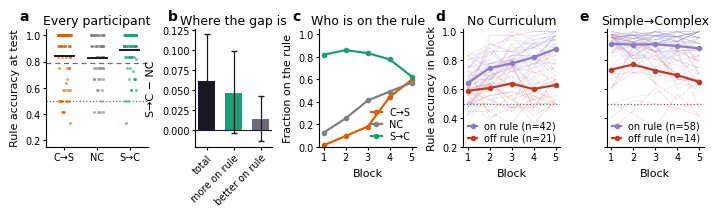

In [4]:
# Supplementary -- the curriculum helps people FIND the rule (not in the main text)
ACC = P.rule_test_accuracy(T)
TOT, COMP, WIT, GG = P.decompose(ACC['standard'], ACC['curriculum'])
BS = P.decompose_boot(ACC['standard'], ACC['curriculum'])
OB = P.on_rule_by_block(LRN, T)
print(f'mixture  total {TOT:+.3f}  composition {COMP:+.3f}  within {WIT:+.3f}  '
      f'({100*COMP/TOT:.0f}% composition)')
CUT_DRAW = 9.5 / 12
FOUND_C, LOST_C = stimColors['Rule'], '#c0392b'
pct = lambda x: (np.exp(x) - 1) * 100
rng4 = np.random.default_rng(0)

fig = plt.figure(figsize=(7.2, 2.0))
gsT = fig.add_gridspec(1, 5, left=.072, right=.985, top=.85, bottom=.26,
                       wspace=.50, width_ratios=[1.05, .80, 1.0, 1.0, 1.0])
A4 = {}

# --- A: every participant's rule accuracy at test -----------------------------
ax = A4['a'] = fig.add_subplot(gsT[0, 0])
for i, c in enumerate(CONDS):
    a = ACC[c]
    ax.scatter(i + rng4.uniform(-.2, .2, len(a)), a, s=5, color=condColors[c],
               alpha=.55, lw=0, zorder=2)
    ax.hlines(a.mean(), i - .32, i + .32, color=INK, lw=1.4, zorder=3)
ax.axhline(CUT_DRAW, color=MUT, lw=LW_REF, ls=(0, (4, 3)), zorder=1)
ax.axhline(.5, color=MUT, lw=LW_REF, ls=':', zorder=1)
ax.set(xticks=range(3), ylim=(.15, 1.05), xlim=(-.55, 2.55), ylabel='Rule accuracy at test')
ax.set_xticklabels([condShort[c] for c in CONDS])
finish(ax, 'Every participant')

# --- B: the decomposition -----------------------------------------------------
ax = A4['b'] = fig.add_subplot(gsT[0, 1])
vals = np.array([TOT, COMP, WIT]); ci = np.nanpercentile(BS, [2.5, 97.5], axis=0)
ax.bar(range(3), vals, color=[INK, condColors['curriculum'], MUT], width=.62, lw=0, zorder=2)
ax.errorbar(range(3), vals, yerr=[vals - ci[0], ci[1] - vals], fmt='none', ecolor=INK,
            elinewidth=LW_REF, capsize=2, zorder=3)
ax.axhline(0, color=INK, lw=LW_SPINE)
ax.set(xticks=range(3), ylabel='S→C − NC')
ax.set_xticklabels(['total', 'more on rule', 'better on rule'], rotation=45,
                   ha='right', rotation_mode='anchor')
finish(ax, 'Where the gap is')

# --- C: fraction on the rule, by block ---------------------------------------
ax = A4['c'] = fig.add_subplot(gsT[0, 2])
for c in CONDS:
    f = OB[c]['frac']
    ax.plot(f.index, f.values, '-o', color=condColors[c], ms=3, lw=LW_DATA,
            label=condShort[c])
ax.set(xticks=range(1, 6), ylim=(0, 1.05), xlabel='Block',
       ylabel='Fraction on the rule')
ax.legend(frameon=False, loc='lower right', handlelength=1.1, labelspacing=.2,
          borderaxespad=.2, fontsize=FS_TICK)
finish(ax, 'Who is on the rule')

# --- D, E: individual rule trajectories, split by test outcome ----------------
for k, (c, ttl) in enumerate([('standard', 'No Curriculum'), ('curriculum', 'Simple→Complex')]):
    ax = A4[f'd{k}'] = fig.add_subplot(gsT[0, 3 + k])
    tr = OB[c]['blk']; isf = tr.index.isin(OB[c]['found'])
    for grp, col, lab in ((isf, FOUND_C, 'on rule'), (~isf, LOST_C, 'off rule')):
        sub = tr.values[grp]
        for row in sub: ax.plot(tr.columns, row, color=col, lw=.4, alpha=.22, zorder=1)
        ax.plot(tr.columns, np.nanmean(sub, 0), '-o', color=col, ms=3, lw=LW_DATA,
                zorder=3, label=f'{lab} (n={grp.sum()})')
    ax.axhline(.5, color=MUT, lw=LW_REF, ls=':', zorder=0)
    ax.set(xticks=range(1, 6), ylim=(.2, 1.02), xlabel='Block')
    if k == 0: ax.set_ylabel('Rule accuracy in block')
    else: ax.set_yticklabels([])
    ax.legend(frameon=False, loc='lower right', handlelength=1.1, labelspacing=.2,
              borderaxespad=.1, fontsize=5.8)
    finish(ax, ttl)

for k, s in zip(['a', 'b', 'c', 'd0', 'd1'], 'abcde'): panel_letter(fig, A4[k], s, dy=.028)
fig.savefig('figures/figureS1_discovery.svg')
fig.savefig('figures/figureS1_discovery.png', dpi=200)
plt.show()

## Figure 4 — Uncompression in the models, and the reaction-time signature

What happens to the networks' representations over learning, with the human reaction-time evidence for the same strategy states appended below.

In [ ]:
# Figure 4 -- uncompression in the yoked networks, on the human timescale
from scipy import stats as _st
from matplotlib.ticker import MaxNLocator
EARLY, LATE = 48, 240
GRID_CONDS = ['standard', 'curriculum']       # complex-to-simple dropped from the projections
PRt_, PRv = R['pr_t'], R['pr']
SR, SE = R['sep_rule'], R['sep_exc']          # task-axis separations, noise-free code
proj = {t: P.task_axes(R['hidden'][t]) for t in (EARLY, LATE)}
LAB8 = P.POLICIES['rule + exceptions']
final_pr = PRv[-1]
exc_acc = np.array([R['final'][i][P.IS_EXC].mean() for i in range(D.P)])

print('final PR and task-axis separation by condition:')
for c in CONDS:
    m = D.cond == c
    print(f'  {condLabel[c]:20s} PR {final_pr[m].mean():.3f} (trough {PRv[:, m].mean(1).min():.3f} '
          f'at trial {PRt_[PRv[:, m].mean(1).argmin()]:3d})   rule sep {SR[-1, m].mean():5.2f}   '
          f'exception sep {SE[-1, m].mean():5.2f}')
for nm, V in (('PR', final_pr), ('exception sep', SE[-1])):
    a_, b_ = V[D.cond == 'curriculum'], V[D.cond == 'standard']
    tt = _st.ttest_ind(a_, b_, equal_var=False)
    print(f'  {nm:<14} S→C − NC = {a_.mean()-b_.mean():+.3f}, t({tt.df:.0f}) = {tt.statistic:.2f}, '
          f'p = {tt.pvalue:.2g}')

def traj_panel(ax, V, ylab, title, mark=(), legend=False):
    for c in CONDS:
        m = D.cond == c
        mu = V[:, m].mean(1); se = V[:, m].std(1, ddof=1) / np.sqrt(m.sum())
        ax.fill_between(PRt_, mu - se, mu + se, color=condColors[c], alpha=.2, lw=0)
        ax.plot(PRt_, mu, color=condColors[c], lw=LW_DATA, label=condShort[c])
    for t in mark: ax.axvline(t, color=MUT, lw=LW_REF, ls=':', zorder=0)
    ax.set(xlabel='Trial', ylabel=ylab, xlim=(-5, D.T + 5), xticks=[0, 120, 240])
    if legend: ax.legend(frameon=False, loc='lower right', handlelength=1.1,
                         labelspacing=.2, borderaxespad=.2, fontsize=FS_TICK)
    finish(ax, title)

gm = np.isin(D.cond, GRID_CONDS)
allx = np.concatenate([proj[t][0][gm].mean(0) for t in (EARLY, LATE)])
ally = np.concatenate([proj[t][1][gm].mean(0) for t in (EARLY, LATE)])
padx, pady = .18 * np.ptp(allx), .30 * np.ptp(ally)
XL = (allx.min() - padx, allx.max() + padx); YL = (ally.min() - pady, ally.max() + pady)

# --- the figure: three columns of model panels, (a, b) | (c, d) | e, with the
# --- human reaction-time signature of the strategies appended below ----------
figw = plt.figure(figsize=(7.2, 5.2))
_s4 = 3.0 / 5.2                     # squeeze the model block into the top
y4 = lambda v: 1 - (1 - v) * _s4
g1 = figw.add_gridspec(2, 1, left=.110, right=.285, top=y4(.90), bottom=y4(.14),
                       hspace=.85)
g2 = figw.add_gridspec(2, 1, left=.345, right=.515, top=y4(.90), bottom=y4(.14),
                       hspace=.85)
g3 = figw.add_gridspec(2, 2, left=.605, right=.895, top=y4(.855), bottom=y4(.14),
                       wspace=.20, hspace=.12)
W5 = {}

# a: final participation ratio as a bar plot. The trajectory it replaces is in the
# supplement. Bars start at 1 because PR = 1 is the measure's floor (all eight stimuli on a
# single axis), not an arbitrary truncation.
ax = W5['a'] = figw.add_subplot(g1[0, 0])
_bx = np.arange(len(CONDS))
_bm = np.array([final_pr[D.cond == c].mean() for c in CONDS])
_be = np.array([final_pr[D.cond == c].std(ddof=1) / np.sqrt((D.cond == c).sum())
                for c in CONDS])
ax.bar(_bx, _bm - 1.0, bottom=1.0, width=.66,
       color=[condColors[c] for c in CONDS], edgecolor='none', zorder=2)
ax.errorbar(_bx, _bm, yerr=_be, fmt='none', ecolor=INK, elinewidth=1.1, capsize=2.6,
            capthick=1.1, zorder=3)
# both curricula against no curriculum -- the contrasts the text reports. The third
# pairwise comparison (S->C vs C->S) is significant too but is never made in the text,
# so it is left off rather than introduced here.
_yb = (_bm + _be).max() + .045
_iNC = CONDS.index('standard')
for _c4 in ('anti_curriculum', 'curriculum'):
    _t4 = _st.ttest_ind(final_pr[D.cond == _c4], final_pr[D.cond == 'standard'],
                        equal_var=False)
    _i1 = CONDS.index(_c4)
    _lo4, _hi4 = sorted((_iNC, _i1))
    ax.plot([_lo4, _lo4, _hi4, _hi4], [_yb, _yb + .022, _yb + .022, _yb], color=INK, lw=.9,
            clip_on=False, zorder=4)
    ax.text((_lo4 + _hi4) / 2, _yb + .028, P.stars(_t4.pvalue) or 'n.s.', ha='center',
            va='bottom', fontsize=FS_TICK, color=INK)
ax.set(xticks=_bx, ylabel='Final participation\nratio', ylim=(1.0, _yb + .105))
ax.set_xticklabels([condShort[c] for c in CONDS], fontsize=FS_TICK)
finish(ax, None)
ax = W5['b'] = figw.add_subplot(g1[1, 0])
for c in CONDS:
    m = D.cond == c
    ax.scatter(final_pr[m], exc_acc[m], s=3, color=condColors[c], alpha=.45, lw=0, zorder=2)
xs, ys, lo, hi = P.ols_band(final_pr, exc_acc)
ax.fill_between(xs, lo, hi, color=INK, alpha=.18, lw=0, zorder=3)
ax.plot(xs, ys, color=INK, lw=LW_DATA, zorder=4)
r_, p_ = _st.pearsonr(final_pr, exc_acc)
ax.annotate(f'r = {r_:+.2f}', xy=(.04, .96), xycoords='axes fraction', ha='left', va='top',
            fontsize=FS_TICK, color=INK)
ax.set(xlabel='Final participation ratio', ylabel='Exception\naccuracy')
finish(ax, None)

W5['c'] = figw.add_subplot(g2[0, 0]); traj_panel(W5['c'], SE, 'Exception axis', None)
W5['d'] = figw.add_subplot(g2[1, 0]); traj_panel(W5['d'], SR, 'Rule axis', None)

for r, (t, rlab) in enumerate([(EARLY, f'Trial {EARLY}'), (LATE, f'Trial {LATE}')]):
    x_, y_ = proj[t]
    for j, c in enumerate(GRID_CONDS):
        ax = W5[f'p{r}{j}'] = figw.add_subplot(g3[r, j])
        m = D.cond == c
        ax.axhline(0, color='#dddddd', lw=.8, zorder=0)
        ax.axvline(0, color='#dddddd', lw=.8, zorder=0)
        for i in range(8):
            ax.scatter(x_[m, i].mean(), y_[m, i].mean(),
                       marker='^' if LAB8[i] == 1 else 'o', s=46,
                       color=stimColors['Exception' if P.IS_EXC[i] else 'Rule'],
                       edgecolor='k', linewidth=.7, zorder=3)
        ax.set(xlim=XL, ylim=YL)
        ax.set_box_aspect(1); ax.set_anchor('C')   # square, centred in its cell
        ax.xaxis.set_major_locator(MaxNLocator(3)); ax.yaxis.set_major_locator(MaxNLocator(3))
        ax.tick_params(labelsize=5.5, length=2, width=.8, pad=1)
        if r == 0: ax.set_title(condLabel[c], fontsize=FS_TITLE, pad=3); ax.set_xticklabels([])
        else: ax.set_xlabel('Rule axis', fontsize=FS_LABEL, labelpad=2)
        if j == 0: ax.set_ylabel(rlab, fontsize=FS_TICK)
        else: ax.set_yticklabels([])
        for sp in ax.spines.values(): sp.set_linewidth(1.1)
figw.text(.540, y4(.50), 'Exception axis', rotation=90, va='center', ha='center', fontsize=FS_LABEL)
hw = [plt.Line2D([], [], ls='none', marker=mk, color=stimColors[st], mec='k', mew=.7,
                 ms=5.6, label=f'{"rule" if st == "Rule" else "exc."} {cl}')
      for st, mk, cl in (('Rule', 'o', 0), ('Rule', '^', 1),
                         ('Exception', 'o', 0), ('Exception', '^', 1))]
figw.legend(handles=hw, frameon=False, fontsize=FS_TICK, loc='center left',
            bbox_to_anchor=(.903, y4(.50)), handlelength=.8, handletextpad=.35, labelspacing=.45)
for k, s in zip(['a', 'b'], 'ab'): panel_letter(figw, W5[k], s, dx=-.062, dy=.040)
for k, s in zip(['c', 'd'], 'cd'): panel_letter(figw, W5[k], s, dx=-.046, dy=.040)
panel_letter(figw, W5['p00'], 'e', dx=-.058, dy=.055)

# --- f-h: the reaction-time signature of the strategies, in people ------------
COST, RTdf = P.rt_cost(LRN)
BYS, MM, MARG = P.rt_by_state(SH, COST)
pct = lambda x: (np.exp(x) - 1) * 100
from scipy import stats as _st
gsR = figw.add_gridspec(1, 3, left=.160, right=.845, top=.325, bottom=.100, wspace=.80,
                        width_ratios=[1.25, 1.0, 1.0])

ax = W5['f'] = figw.add_subplot(gsR[0, 0])
ax.axhline(0, color=INK, lw=LW_REF, alpha=.6)
for c in CONDS:
    q = COST[COST.cond == c].groupby('block')['cost'].agg(['mean', 'sem'])
    ax.errorbar(q.index, pct(q['mean']), yerr=pct(q['mean'] + q['sem']) - pct(q['mean']),
                fmt='-o', color=condColors[c], ms=3.6, lw=2.2, capsize=2,
                elinewidth=1.4, capthick=1.4, label=condShort[c])
ax.set(xticks=range(1, 6), xlabel='Block', ylabel='Exception RT cost (%)')
ax.legend(frameon=False, loc='upper left', handlelength=1.1, labelspacing=.2,
          borderaxespad=.2, fontsize=FS_TICK)
finish(ax, 'Cost emerges over training')

sub = [s_ for s_ in STATES if (BYS.state == s_).sum() >= 5]
xr = np.arange(len(sub))
raw_m = np.array([BYS[BYS.state == s_]['cost'].mean() for s_ in sub])
raw_e = np.array([BYS[BYS.state == s_]['cost'].sem() for s_ in sub])
raw_p = [_st.ttest_1samp(BYS[BYS.state == s_]['cost'], 0).pvalue for s_ in sub]
LBL = [SHORT[STATES.index(s_)] for s_ in sub]
ax = W5['g'] = figw.add_subplot(gsR[0, 1])
ax.axhline(0, color=INK, lw=LW_REF, alpha=.6)
top = pct(raw_m + raw_e)
ax.bar(xr, pct(raw_m), yerr=top - pct(raw_m), width=.7,
       color=[stateColors[s_] for s_ in sub], edgecolor='k', linewidth=.9,
       error_kw=dict(lw=1.4, capsize=2, capthick=1.4))
for xi, t_, p_ in zip(xr, top, raw_p):
    if P.stars(p_):
        ax.annotate(P.stars(p_), xy=(xi, t_), xytext=(0, 2), textcoords='offset points',
                    ha='center', va='bottom', fontsize=FS_TICK, color=INK)
ax.set(xticks=xr, xlim=(-.6, len(sub) - .4), ylim=(None, 1.25 * top.max()),
       ylabel='Exception RT cost (%)')
ax.set_xticklabels(LBL, rotation=45, ha='right', rotation_mode='anchor')
finish(ax, 'By strategy (raw)')

ax = W5['h'] = figw.add_subplot(gsR[0, 2])
coef = np.array([MM.params.get(f'C(state)[T.{s_}]', 0.0) for s_ in sub])
cse = np.array([MM.bse.get(f'C(state)[T.{s_}]', 0.0) for s_ in sub])
cp = [MM.pvalues.get(f'C(state)[T.{s_}]', np.nan) for s_ in sub]
ax.axhline(0, color=INK, lw=LW_REF, alpha=.6)
ax.bar(xr, coef, yerr=cse, width=.7, color=[stateColors[s_] for s_ in sub],
       edgecolor='k', linewidth=.9, error_kw=dict(lw=1.4, capsize=2, capthick=1.4))
for xi, m_, e_, p_ in zip(xr, coef, cse, cp):
    if not np.isnan(p_) and P.stars(p_):
        ax.annotate(P.stars(p_), xy=(xi, m_ + e_), xytext=(0, 2), textcoords='offset points',
                    ha='center', va='bottom', fontsize=FS_TICK, color=INK)
ax.annotate('ref.', xy=(0, 0), xytext=(0, 3), textcoords='offset points', ha='center',
            va='bottom', fontsize=FS_TICK, color=MUT)
pad = .3 * (coef + cse).max()
ax.set(xticks=xr, xlim=(-.6, len(sub) - .4),
       ylim=((coef - cse).min() - pad, (coef + cse).max() + pad),
       ylabel='Estimate vs random\n(log RT)')
ax.set_xticklabels(LBL, rotation=45, ha='right', rotation_mode='anchor')
finish(ax, 'By strategy (model)')
print(f'{len(BYS)} participant-blocks from {BYS.sid.nunique()} participants')

P.row_icon(figw, 'network', .022, y4(.52))
P.row_icon(figw, 'human', .060, .2125)
for k, s_ in zip(['f', 'g', 'h'], 'fgh'):
    panel_letter(figw, W5[k], s_, dx=-.062, dy=.040)

figw.savefig('figures/figure4_uncompression_and_rt.svg')
figw.savefig('figures/figure4_uncompression_and_rt.png', dpi=200)
plt.show()

In [ ]:
# Supplementary: the participation-ratio trajectory, which was Figure 4a before the
# final-PR bar plot replaced it. Panels c and d of Figure 4 remain trajectories, so this
# supplies the matching time course for dimensionality itself.
figS6 = plt.figure(figsize=(3.3, 2.5))
axS = figS6.add_subplot(111)
for c in CONDS:
    m = D.cond == c
    mu = PRv[:, m].mean(1); se = PRv[:, m].std(1, ddof=1) / np.sqrt(m.sum())
    axS.fill_between(PRt_, mu - se, mu + se, color=condColors[c], alpha=.2, lw=0)
    axS.plot(PRt_, mu, color=condColors[c], lw=LW_DATA, label=condShort[c])
for t in (EARLY, LATE):
    axS.axvline(t, color=MUT, lw=LW_REF, ls=':', zorder=0)
axS.set(xlabel='Trial', ylabel='Participation ratio', xlim=(-5, D.T + 5), xticks=[0, 120, 240])
axS.legend(frameon=False, loc='lower right', handlelength=1.1, labelspacing=.2,
           borderaxespad=.2, fontsize=FS_TICK)
finish(axS, None)
figS6.savefig('figures/figureS6_pr_trajectory.svg', bbox_inches='tight')
figS6.savefig('figures/figureS6_pr_trajectory.png', dpi=200, bbox_inches='tight')
print('wrote figureS6_pr_trajectory')

## Figure 5 — The Experiment 2 model

One network per participant, trained through both phases on that participant's own trial
sequence in their own physical feature coding. Every hyperparameter is inherited from
Experiment 1; the two lapse rates are the only fitted quantities. The weight-scale pullback
explored earlier is switched off here (α = 0) — see the supplement for what it would buy.

In [ ]:
# Figure 5 -- the Experiment 2 yoked model: compression during pretraining, and what it
# costs in the R+E phase. Every hyperparameter is inherited from Experiment 1 and there is no
# weight-scale pullback (alpha = 0); one lapse per phase is the only thing fitted.
from matplotlib.patches import FancyBboxPatch
import statsmodels.formula.api as _sf
from scipy import stats as _stt

D2y = P.YokedExp2Data()
R2y = P.cached('exp2', lambda: P.run_yoked_exp2(D2y, probe_every=8))
NET, HUM = P.exp2_curves(D2y, R2y), P.exp2_human_curves()
print('config:', R2y['cfg'])
print('PR after pretraining:  1-D {Simple:.3f}   XOR {XOR:.3f}'.format(**NET['pr']))
_rm = np.sqrt(np.mean([(NET[('test', c, p, n)] - HUM[('test', c, p, n)]) ** 2
                       for c in P.E2_CUR for p in ('Simple', 'XOR')
                       for n in ('Rule', 'Exception')]))
print(f'test RMSE against the eight human cells = {_rm:.3f}')

# ---- the model's representations (was a standalone figure; now panels f-h) ----
RM = R2y
_p1, _c1 = (D2y.pre == 'Simple'), (D2y.cur == 'Simple To Complex')
CUR_C = {'NC': condColors['standard'], 'S→C': condColors['curriculum']}
MKm = {'1-D': 'o', 'XOR': 's'}
_EX = np.where(P.IS_EXC)[0]
_w = D2y.msk_t & D2y.exc_t
_prt = (1 - .24) * RM['pc_test'] + .12
_exc = np.where(_w.sum(1) > 0, (_prt * _w).sum(1) / np.maximum(_w.sum(1), 1), np.nan)
MECH = pd.DataFrame(dict(
    pr_end=RM['pr_end'], pr_pre=RM['pr_boundary'], sep=RM['sep_exc'],
    lsep=np.abs(RM['logit'][:, _EX[0]] - RM['logit'][:, _EX[1]]), exc=_exc,
    pre=np.where(_p1, '1-D', 'XOR'), cur=np.where(_c1, 'S→C', 'NC'))).dropna()

# The simple effects are what panel a marks. The INTERACTION -- the test of whether the
# curriculum helps compressed networks more -- is not significant for any of these, so the
# stars say "the curriculum works here and not there", never "it works more here".
SIMPLE = {}
for _y in ('pr_end', 'sep', 'lsep'):
    _m = _sf.ols(f'{_y} ~ C(pre)*C(cur)', data=MECH).fit()
    _k = [j for j in _m.params.index if ':' in j][0]
    print(f'{_y:8s} interaction b = {_m.params[_k]:+.3f}, p = {_m.pvalues[_k]:.3g}   simple effects:')
    for _p in ('1-D', 'XOR'):
        _a = MECH[(MECH.pre == _p) & (MECH.cur == 'NC')][_y]
        _b = MECH[(MECH.pre == _p) & (MECH.cur == 'S→C')][_y]
        _t, _pv = _stt.ttest_ind(_b, _a, equal_var=False)
        SIMPLE[(_y, _p)] = _pv
        print(f'    {_p:4s} {_a.mean():7.3f} -> {_b.mean():7.3f}  Δ = {_b.mean()-_a.mean():+.3f}, '
              f't = {_t:+.2f}, p = {_pv:.3g}')


PRE_C = {'Simple': INK, 'XOR': MUT}          # pretraining condition: neutral pair
MK5 = {'Simple': 'o', 'XOR': 's'}            # pretraining: marker shape
# Line style is available as a third cue for pretraining but is switched off: the open vs
# filled markers carry it well enough on their own, and dashes add clutter. To bring it
# back, set XOR to (0, (3.2, 1.3)) -- see figure5_exp2_model_DASHED.svg for how that looks.
LS5 = {'Simple': '-', 'XOR': '-'}
def mk5(p, col):                             # ... plus open vs filled markers
    return dict(marker=MK5[p], ls=LS5[p], color=col, mew=.9, mec=col,
                mfc='white' if p == 'XOR' else col)
NBIN, PER_BIN = 10, 24
BINS = (np.arange(1, NBIN + 1) - .5) * PER_BIN          # bin centres, in trials
CASCADES = ('pretraining', 'learning', 'test')


def draw_design(fig, ax):
    """Experiment 2's design: the three phases, with the 2x2 as an explicit crossing."""
    ax.set(xlim=(0, 1), ylim=(0, 1)); ax.axis('off')
    W_in, H_in = fig.get_size_inches()
    bb = ax.get_position(); axw, axh = W_in * bb.width, H_in * bb.height
    im = {n: plt.imread(f'assets/cascade_{n}.png') for n in CASCADES}
    TOP, WID = .93, .215
    CX = {'pretraining': .248, 'learning': .500, 'test': .752}
    title = {'pretraining': 'Pretraining\n240 trials', 'learning': 'R+E learning\n240 trials',
             'test': 'Test\n16 trials, no feedback'}
    for n in CASCADES:
        a = im[n]; w = WID * (a.shape[1] / im['pretraining'].shape[1])
        h = w * axw * (a.shape[0] / a.shape[1]) / axh        # keep the true aspect
        ax.imshow(a, extent=(CX[n] - w/2, CX[n] + w/2, TOP - h, TOP), aspect='auto', zorder=3)
        ax.text(CX[n], .985, title[n], ha='center', va='bottom', fontsize=FS_TICK,
                color=INK, linespacing=1.25)

    def chip(xc, y, w, txt, h=.115):
        ax.add_patch(FancyBboxPatch((xc - w/2, y - h/2), w, h, zorder=4,
                     boxstyle='round,pad=0,rounding_size=.03', linewidth=.9,
                     edgecolor=INK, facecolor='white'))
        ax.text(xc, y, txt, ha='center', va='center', fontsize=FS_TICK, color=INK, zorder=5)
        return xc - w/2, xc + w/2
    YA, YB = .255, .085
    BOX = .170                                  # one width: the phases are equally long
    pre = [chip(.248, YA, BOX, '1-D'), chip(.248, YB, BOX, 'XOR')]
    cur = [chip(.500, YA, BOX, 'No curriculum'), chip(.500, YB, BOX, 'Simple to Complex')]
    for i, yp in enumerate((YA, YB)):              # every pretraining x every curriculum
        for j, yc in enumerate((YA, YB)):
            ax.plot([pre[i][1] + .014, cur[j][0] - .014], [yp, yc], color=INK, lw=.7,
                    alpha=.6, zorder=2, solid_capstyle='round')
    ax.annotate('', xy=(.671, .170), xytext=(cur[0][1] + .016, .170), zorder=2,
                arrowprops=dict(arrowstyle='-|>', color=INK, lw=.9, shrinkA=0, shrinkB=0))


def draw_exp2(NET, HUM, fname, mech=None, simple=None):
    """The Figure 5 layout, so a model variant can be drawn exactly the same way.

    With `mech` (plus its simple-effect p-values) the figure grows a third row showing what
    the curriculum does to the representation; the supplementary variants pass neither, so
    they keep the shorter layout.
    """
    tall = mech is not None
    HGT = 8.6 if tall else 6.6
    _s = 6.6 / HGT                          # squeeze the existing rows into the top
    yy = lambda v: 1 - (1 - v) * _s
    fig5 = plt.figure(figsize=(7.2, HGT))
    draw_design(fig5, fig5.add_axes([.075, yy(.700), .910, .300 * _s]))
    g5a = fig5.add_gridspec(1, 4, left=.075, right=.985, top=yy(.617), bottom=yy(.430), wspace=.42)
    g5b = fig5.add_gridspec(1, 4, left=.075, right=.985, top=yy(.273), bottom=yy(.078), wspace=.42)
    A5 = {}

    # --- b, c: the pretraining phase -----------------------------------------
    for j, (src, who) in enumerate(((HUM, 'humans'), (NET, 'networks'))):
        ax = A5['ab'[j]] = fig5.add_subplot(g5a[0, j])
        for p in ('Simple', 'XOR'):
            _mu, _se = src['pre'][p], src['pre_sem'][p]
            ax.fill_between(BINS, _mu - _se, _mu + _se, color=PRE_C[p], alpha=.25, lw=0,
                            zorder=1)
            ax.plot(BINS, _mu, ms=3.2, lw=1.6, zorder=2, **mk5(p, PRE_C[p]),
                    label=P.E2_LABEL[p] + ' pretraining')
        ax.set(xlim=(0, NBIN * PER_BIN), xticks=[0, 120, 240], ylim=(.45, 1.0), xlabel='Trial')
        ax.set_title(f'Pretraining, {who}', fontsize=FS_TITLE, pad=3)
        if j == 0:
            ax.set_ylabel('Accuracy')
            ax.legend(frameon=False, loc='lower right', handlelength=1.2, labelspacing=.25,
                      borderaxespad=.2, fontsize=FS_TICK)
        finish(ax, None)
    axi = A5['b'].inset_axes([.545, .165, .385, .325])
    axi.bar([0, 1], [NET['pr']['Simple'], NET['pr']['XOR']], width=.7,
            color=[PRE_C['Simple'], PRE_C['XOR']], edgecolor='k', linewidth=.3)
    axi.set(xlim=(-.6, 1.6), xticks=[0, 1], ylim=(0, 3.2), yticks=[0, 1, 2, 3])
    axi.set_xticklabels(['1-D', 'XOR'], fontsize=FS_TICK - 1)
    axi.set_title('PR after\npretraining', fontsize=FS_TICK - 1, pad=1.5, linespacing=1.1)
    axi.tick_params(labelsize=FS_TICK - 1, length=1.8, width=.6)
    for sp in ('top', 'right'):
        axi.spines[sp].set_visible(False)
    for sp in ('left', 'bottom'):
        axi.spines[sp].set_linewidth(.6)

    # --- d, e: test, humans first. Exceptions left of each tick, rule right ---
    for j, (src, who) in enumerate(((HUM, 'humans'), (NET, 'networks'))):
        ax = A5['cd'[j]] = fig5.add_subplot(g5a[0, 2 + j])
        for i, cur in enumerate(P.E2_CUR):
            for q, st in enumerate(('Exception', 'Rule')):
                for k, p in enumerate(('Simple', 'XOR')):
                    x = i + (q - .5) * .42 + (k - .5) * .17
                    y = src[('test', cur, p, st)]
                    ax.errorbar(x, y, src[('test_sem', cur, p, st)],
                                color=stimColors[st], lw=1.1, capsize=2, zorder=2)
                    ax.plot(x, y, ms=4.4, zorder=3, ls='none',
                            **{k: v for k, v in mk5(p, stimColors[st]).items()
                               if k != 'ls'})
        ax.set(xlim=(-.62, 1.62), xticks=[0, 1], ylim=(.45, 1.0))
        ax.set_xticklabels(['No curr.', 'S→C'])
        ax.set_title(f'Test, {who}', fontsize=FS_TITLE, pad=3)
        if j == 0:
            ax.set_ylabel('Accuracy')
        finish(ax, None)

    # --- f-i: the R+E phase, humans then networks within each curriculum ------
    panels = ((HUM, 'humans', P.E2_CUR[0]), (NET, 'networks', P.E2_CUR[0]),
              (HUM, 'humans', P.E2_CUR[1]), (NET, 'networks', P.E2_CUR[1]))
    for j, (src, who, cur) in enumerate(panels):
        ax = A5['efgh'[j]] = fig5.add_subplot(g5b[0, j])
        for p in ('Simple', 'XOR'):
            for st in ('Rule', 'Exception'):
                _mu = np.asarray(src[(cur, p, st)], float)
                _se = np.asarray(src[('sem', cur, p, st)], float)
                ax.fill_between(BINS, _mu - _se, _mu + _se, color=stimColors[st],
                                alpha=.25, lw=0, zorder=1)
                ax.plot(BINS, _mu, ms=3.4, lw=1.5, zorder=2, **mk5(p, stimColors[st]))
        ax.axhline(.5, color=MUT, lw=LW_REF, ls=(0, (1, 2.2)), zorder=0)
        ax.set(xlim=(0, NBIN * PER_BIN), xticks=[0, 120, 240], ylim=(0, 1.0), xlabel='Trial')
        nice = 'No curriculum' if cur == P.E2_CUR[0] else 'Simple to Complex'
        ax.set_title(f'{nice},\n{who}', fontsize=FS_TITLE, pad=3, linespacing=1.15)
        if j == 0:
            ax.set_ylabel('R+E accuracy')
        finish(ax, None)

    h5 = ([plt.Line2D([], [], color=stimColors[st], lw=1.6, label=st.lower())
           for st in ('Rule', 'Exception')]
          + [plt.Line2D([], [], lw=1.6, ms=4.6, label=P.E2_LABEL[p], **mk5(p, MUT))
             for p in ('Simple', 'XOR')])
    fig5.legend(handles=h5, frameon=False, fontsize=FS_TICK, ncol=4, loc='center',
                bbox_to_anchor=(.53, yy(.364)), handlelength=1.3, columnspacing=1.6,
                handletextpad=.5)
    fig5.text(.165, yy(.986), 'a', fontsize=FS_TITLE + 1, fontweight='bold', va='bottom')
    for k, lab in zip('abcdefgh', 'bcdefghi'):
        panel_letter(fig5, A5[k], lab, dx=-.050, dy=.030)
    if tall:
        # --- j, k: what the curriculum does to the model's representation -----
        gsM = fig5.add_gridspec(1, 2, left=.258, right=.742, top=.220, bottom=.070,
                                wspace=.52, width_ratios=[1, 1.30])
        CUR_C = {'NC': condColors['standard'], 'S→C': condColors['curriculum']}
        MKm = {'1-D': 'o', 'XOR': 's'}
        ax = A5['i'] = fig5.add_subplot(gsM[0, 0])
        ylim = (2.33, 3.12)
        for i, p_ in enumerate(('1-D', 'XOR')):
            top = -np.inf
            for c_ in ('NC', 'S→C'):
                g = mech[(mech.pre == p_) & (mech.cur == c_)].pr_end
                x = i + (.19 if c_ == 'S→C' else -.19)
                ax.errorbar(x, g.mean(), g.sem(), color=CUR_C[c_], lw=1.3, capsize=2.5, zorder=2)
                ax.plot(x, g.mean(), MKm[p_], ms=4.6, color=CUR_C[c_], zorder=3,
                        label=c_ if i == 0 else None)
                top = max(top, g.mean() + g.sem())
            h_ = ylim[1] - ylim[0]
            yb = top + .09 * h_          # brackets mark the SIMPLE effects, not the interaction
            ax.plot([i - .19, i - .19, i + .19, i + .19],
                    [yb - .025 * h_, yb, yb, yb - .025 * h_], color=INK, lw=.9, zorder=4)
            st_ = P.stars(simple[('pr_end', p_)])
            ax.text(i, yb + .015 * h_, st_ or 'n.s.', ha='center', va='bottom', color=INK,
                    fontsize=(FS_LABEL + 1) if st_ else FS_TICK - 1, zorder=5)
        ax.set(xlim=(-.55, 1.55), xticks=[0, 1], ylim=ylim, xlabel='Pretraining',
               ylabel='Final participation ratio')
        ax.set_xticklabels(['1-D', 'XOR'])
        ax.legend(frameon=False, loc='upper left', handlelength=.9, labelspacing=.2,
                  borderaxespad=.2, fontsize=FS_TICK - 1)
        finish(ax, None)

        ax = A5['j'] = fig5.add_subplot(gsM[0, 1])
        _fit = {}
        for c_ in ('NC', 'S→C'):
            g = mech[mech.cur == c_].dropna(subset=['pr_pre', 'exc'])
            ax.scatter(g.pr_pre, g.exc, s=3, color=CUR_C[c_], alpha=.28, lw=0, zorder=2)
            xs, ys, lo, hi = P.ols_band(g.pr_pre.values, g.exc.values)
            ax.fill_between(xs, lo, hi, color=CUR_C[c_], alpha=.22, lw=0, zorder=3)
            ax.plot(xs, ys, color=CUR_C[c_], lw=LW_DATA, zorder=4, label=c_)
            _fit[c_] = np.polyfit(g.pr_pre.values, g.exc.values, 1)
        for xg in (mech[mech.pre == '1-D'].pr_pre.mean(), mech[mech.pre == 'XOR'].pr_pre.mean()):
            y0, y1 = [np.polyval(_fit[c], xg) for c in ('NC', 'S→C')]
            ax.plot([xg, xg], [y0, y1], color=INK, lw=1.0, zorder=6, solid_capstyle='butt')
            for yv in (y0, y1):
                ax.plot([xg - .035, xg + .035], [yv, yv], color=INK, lw=1.0, zorder=6)
            ax.annotate(f'{y1 - y0:+.3f}', xy=(xg, max(y0, y1)), xytext=(0, 4),
                        textcoords='offset points', ha='center', va='bottom',
                        fontsize=FS_TICK - 1, color=INK, zorder=7,
                        bbox=dict(boxstyle='square,pad=.12', fc='white', ec='none', alpha=.8))
        ax.set(xlabel='Participation ratio after pretraining', ylabel='Exception accuracy',
               ylim=(.38, .93))
        ax.legend(frameon=False, loc='lower right', handlelength=1.1, labelspacing=.2,
                  borderaxespad=.2, fontsize=FS_TICK - 1)
        finish(ax, None)
        for _n, _l in zip('ij', 'jk'):
            panel_letter(fig5, A5[_n], _l, dx=-.058, dy=.004)
    fig5.savefig('figures/' + fname + '.svg')
    fig5.savefig('figures/' + fname + '.png', dpi=400)
    plt.show()
    return fig5


draw_exp2(NET, HUM, 'figure5_exp2_model', mech=MECH, simple=SIMPLE)

## Supplementary — representation and readout (Experiment 2)

The exception-axis separation dropped from Figure 5, shown with the matching readout measure. A compressed prior degrades both; the curriculum repairs both, and brings a 1-D-pretrained network to almost exactly where an XOR-pretrained one starts without a curriculum.

In [ ]:
# Supplementary -- the representational cost of a compressed prior, and the curriculum's
# repair of it. The exception-axis separation says what the hidden code carries; the logit
# separation says how much of it the readout actually uses. Both improve with a
# high-dimensional prior AND with a curriculum, by similar amounts; the pretraining x
# curriculum interaction is not significant for either (p = .13 and p = .06), so the
# brackets below mark the simple effects only.
figR = plt.figure(figsize=(5.2, 2.4))
gR = figR.add_gridspec(1, 2, left=.115, right=.985, top=.845, bottom=.235, wspace=.55)
AR = {}
for j, (col, ylab, ttl, ylim) in enumerate(
        (('sep', 'Exception-axis separation', 'Representation', (5.45, 7.75)),
         ('lsep', 'Exception logit separation', 'Readout', (14.8, 28.5)))):
    ax = AR['ab'[j]] = figR.add_subplot(gR[0, j])
    for i, p_ in enumerate(('1-D', 'XOR')):
        top = -np.inf
        for c_ in ('NC', 'S→C'):
            g = MECH[(MECH.pre == p_) & (MECH.cur == c_)][col]
            x = i + (.19 if c_ == 'S→C' else -.19)
            ax.errorbar(x, g.mean(), g.sem(), color=CUR_C[c_], lw=1.3, capsize=2.5, zorder=2)
            ax.plot(x, g.mean(), MKm[p_], ms=4.6, color=CUR_C[c_], zorder=3,
                    label=c_ if (i == 0 and j == 0) else None)
            top = max(top, g.mean() + g.sem())
        h_ = ylim[1] - ylim[0]
        yb = top + .09 * h_
        ax.plot([i - .19, i - .19, i + .19, i + .19],
                [yb - .025 * h_, yb, yb, yb - .025 * h_], color=INK, lw=.9, zorder=4)
        st_ = P.stars(SIMPLE[(col, p_)])
        ax.text(i, yb + .015 * h_, st_ or 'n.s.', ha='center', va='bottom', color=INK,
                fontsize=(FS_LABEL + 1) if st_ else FS_TICK - 1, zorder=5)
    ax.set(xlim=(-.55, 1.55), xticks=[0, 1], ylim=ylim, ylabel=ylab, xlabel='Pretraining')
    ax.set_xticklabels(['1-D', 'XOR'])
    ax.set_title(ttl, fontsize=FS_TITLE, pad=3)
    if j == 0:
        ax.legend(frameon=False, loc='upper left', handlelength=.9, labelspacing=.2,
                  borderaxespad=.2, fontsize=FS_TICK - 1)
    finish(ax, None)
print('1-D with a curriculum vs XOR without: '
      f"separation {MECH[(MECH.pre=='1-D')&(MECH.cur=='S→C')].sep.mean():.3f} vs "
      f"{MECH[(MECH.pre=='XOR')&(MECH.cur=='NC')].sep.mean():.3f};  logit "
      f"{MECH[(MECH.pre=='1-D')&(MECH.cur=='S→C')].lsep.mean():.2f} vs "
      f"{MECH[(MECH.pre=='XOR')&(MECH.cur=='NC')].lsep.mean():.2f}")
for k in 'ab':
    panel_letter(figR, AR[k], k, dx=-.075, dy=.055)
figR.savefig('figures/figureS5_exp2_representation.svg')
figR.savefig('figures/figureS5_exp2_representation.png', dpi=400)
plt.show()

In [ ]:
# The key interaction in the model, on the networks' continuous outputs.
#
# Two ways to ask this, and they give different answers. Sampling a binary response per test
# trial and fitting the human GLMM asks "would an experiment with 1027 networks detect this?"
# -- 16 binary trials per network discards most of the model's information, and the answer is
# no (3-way +0.18 log-odds, significant in 2/10 seeds). Using the continuous P(correct), as
# the earlier non-yoked modelling did, asks whether the effect is present in the model at all,
# and the answer is yes. The magnitude is the honest caveat either way: about a third of the
# human effect on the accuracy scale.
_lab = ('3-way (exc − rule)', 'pre × cur on RULE ', 'pre × cur on EXCEPT')
print('Continuous per-network test accuracy, SEs clustered by network:\n')
for _nm, _kw, _lap in (('alpha = 0 (Figure 5)', {}, 0.24), ('lr_re = 0.5', dict(lr_re=0.5), 0.18)):
    _R = R2y if not _kw else P.cached('exp2_slow_lr',
                                     lambda: P.run_yoked_exp2(D2y, cfg=_kw))
    _st = P.exp2_threeway(P.exp2_test_accuracy_long(D2y, _R, lapse_re=_lap))
    print(f'  {_nm}')
    for _n, (_b, _t, _p) in zip(_lab, _st):
        print(f'     {_n}  b = {_b:+.4f}  t = {_t:+5.2f}  p = {_p:.2g}')
_hb = {p: HUM[('test', P.E2_CUR[1], p, 'Exception')] - HUM[('test', P.E2_CUR[0], p, 'Exception')]
       for p in ('Simple', 'XOR')}
print(f'\n  humans, same scale: pre × cur on exceptions = {_hb["Simple"] - _hb["XOR"]:+.4f}'
      f'   (their GLMM on binary choices: +0.930 log-odds, p = .006)')

## Supplementary — a slower R+E phase

The networks converge to about 0.74 on exceptions whatever their pretraining, so the pretraining difference closes by the end of the phase. Halving the learning rate in the R+E phase leaves them where it is still visible. It improves the fit, the accuracy levels and the pretraining effect, and leaves the key interaction where every other intervention leaves it.

In [ ]:
# Supplementary -- the same model with the R+E phase run at half the Experiment 1 learning
# rate (lr_re = 0.5, R+E lapse refitted to 0.18). The networks otherwise converge to ~0.74 on
# exceptions whatever their pretraining, which closes the gap by the end of the phase; smaller
# steps leave them where the pretraining difference is still visible. This buys the LEVELS and
# the pretraining effect, not the key interaction -- nothing tried moves that.
R2slow = P.cached('exp2_slow_lr',
                  lambda: P.run_yoked_exp2(D2y, cfg=dict(lr_re=0.5)))
SLOW = P.exp2_curves(D2y, R2slow, lapse_re=0.18)
NCc, SCc = P.E2_CUR
for nm, c in (('baseline   ', NET), ('lr_re = 0.5', SLOW)):
    ben = {p: c[('test', SCc, p, 'Exception')] - c[('test', NCc, p, 'Exception')]
           for p in ('Simple', 'XOR')}
    pre = c[('test', NCc, 'Simple', 'Exception')] - c[('test', NCc, 'XOR', 'Exception')]
    rm = np.sqrt(np.mean([(c[('test', k, p, n)] - HUM[('test', k, p, n)]) ** 2
                          for k in P.E2_CUR for p in ('Simple', 'XOR')
                          for n in ('Rule', 'Exception')]))
    print(f'{nm}  key interaction {ben["Simple"] - ben["XOR"]:+.3f}   '
          f'pretraining effect {pre:+.3f}   NC 1-D exc '
          f'{c[("test", NCc, "Simple", "Exception")]:.3f}   test RMSE {rm:.3f}')
_hb = {p: HUM[('test', SCc, p, 'Exception')] - HUM[('test', NCc, p, 'Exception')]
       for p in ('Simple', 'XOR')}
print(f'humans       key interaction {_hb["Simple"] - _hb["XOR"]:+.3f}   '
      f'pretraining effect '
      f'{HUM[("test", NCc, "Simple", "Exception")] - HUM[("test", NCc, "XOR", "Exception")]:+.3f}'
      f'   NC 1-D exc {HUM[("test", NCc, "Simple", "Exception")]:.3f}')

draw_exp2(SLOW, HUM, 'figureS4_exp2_slow_lr')

## Supplementary — the weight-scale pullback

Figure 5 uses no pullback. This is the same model with α = 0.1, and a sweep over α across
five seeds. The pullback improves the fit to the eight test cells but does not produce the
key interaction, and it erodes the pretraining effect, which reverses sign by α = 0.3.

In [ ]:
# Supplementary -- the Experiment 2 model WITH the weight-scale pullback (alpha = 0.1), and
# a multi-seed sweep over alpha. Reuses D2y from the Figure 5 cell, which uses alpha = 0.
import os

def _key(c):
    """Curriculum benefit on test exceptions, 1-D pretraining minus XOR."""
    b = {p: c[('test', P.E2_CUR[1], p, 'Exception')] - c[('test', P.E2_CUR[0], p, 'Exception')]
         for p in ('Simple', 'XOR')}
    return b['Simple'] - b['XOR']

def _pre_effect(c):
    """1-D minus XOR on no-curriculum test exceptions. Humans are NEGATIVE (-0.099):
    a compressed prior leaves them WORSE on exceptions. This is the constraint that stops
    alpha being pushed up to where the fit is best."""
    return (c[('test', P.E2_CUR[0], 'Simple', 'Exception')]
            - c[('test', P.E2_CUR[0], 'XOR', 'Exception')])

def _rmse(c):
    return np.sqrt(np.mean([(c[('test', k, p, n)] - HUM[('test', k, p, n)]) ** 2
                            for k in P.E2_CUR for p in ('Simple', 'XOR')
                            for n in ('Rule', 'Exception')]))

# Sweep alpha over several seeds. One seed per alpha is not enough to read this sweep:
# the seed spread is as large as the whole effect of alpha on the interaction.
ALPHAS, NSEED = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40], 5
CACHE5 = 'results/figureS3_alpha_sweep3.npy'
NUL = P.exp2_curves(D2y, P.cached('exp2_alpha010',
                   lambda: P.run_yoked_exp2(D2y, cfg=dict(alpha=0.10))))
if os.path.exists(CACHE5):
    SW = np.load(CACHE5)
else:
    SW = np.zeros((len(ALPHAS), NSEED, 3))
    for i, _a in enumerate(ALPHAS):
        for sd in range(NSEED):
            c = P.exp2_curves(D2y, P.run_yoked_exp2(D2y, cfg=dict(alpha=_a), seed=sd))
            SW[i, sd] = (_key(c), _rmse(c), _pre_effect(c))
    np.save(CACHE5, SW)
HUM_KEY, HUM_PRE = _key(HUM), _pre_effect(HUM)
print(f'human: key interaction {HUM_KEY:+.3f}, pretraining effect {HUM_PRE:+.3f}')
print(f'{"alpha":>7} {"interaction":>18} {"pretrain effect":>21} {"test RMSE":>16}  ({NSEED} seeds)')
for i, _a in enumerate(ALPHAS):
    k, r, e = SW[i, :, 0], SW[i, :, 1], SW[i, :, 2]
    bad = '  <- wrong sign' if e.mean() > 0 else ''
    print(f'{_a:7.2f} {k.mean():+8.3f} ± {k.std():.3f} {e.mean():+11.3f} ± {e.std():.3f}'
          f'     {r.mean():.3f} ± {r.std():.3f}{bad}')
print('\nalpha does NOT buy the key interaction: it is flat and well inside the seed spread\n'
      'at every value. It trades the qualitative pattern against the quantitative fit --\n'
      'the RMSE minimum sits at alpha 0.2, where the pretraining effect has already gone,\n'
      'and the effect reverses sign by alpha 0.3. alpha = 0.1 is a compromise, not an optimum.')

figT = plt.figure(figsize=(7.2, 2.6))
gT = figT.add_gridspec(1, 5, left=.068, right=.980, top=.845, bottom=.235, wspace=.60,
                       width_ratios=[1, .88, 1, 1, 1.5])
AT = {}

ax = AT['a'] = figT.add_subplot(gT[0, 0])           # pretraining is unaffected by alpha
for p in ('Simple', 'XOR'):
    ax.plot(BINS, NUL['pre'][p], '-' + MK5[p], color=PRE_C[p], ms=3.0, lw=1.5,
            label=P.E2_LABEL[p] + ' pretraining')
ax.set(xlim=(0, NBIN * PER_BIN), xticks=[0, 120, 240], ylim=(.45, 1.0), xlabel='Trial',
       ylabel='Accuracy')
ax.set_title('Pretraining', fontsize=FS_TITLE, pad=3)   # unaffected by alpha
ax.legend(frameon=False, loc='lower right', handlelength=1.2, labelspacing=.25,
          borderaxespad=.2, fontsize=FS_TICK - 1)
finish(ax, None)

ax = AT['b'] = figT.add_subplot(gT[0, 1])           # test, alpha = 0
for i, cur in enumerate(P.E2_CUR):
    for k, p in enumerate(('Simple', 'XOR')):
        for st in ('Rule', 'Exception'):
            ax.plot(i + (k - .5) * .34, NUL[('test', cur, p, st)], MK5[p],
                    color=stimColors[st], ms=4.4, zorder=3)
ax.set(xlim=(-.55, 1.55), xticks=[0, 1], ylim=(.45, 1.0), ylabel='Accuracy')
ax.set_xticklabels(['No curr.', 'S→C'])
ax.set_title('Test', fontsize=FS_TITLE, pad=3)
finish(ax, None)

for j, cur in enumerate(P.E2_CUR):                  # the R+E phase, alpha = 0
    ax = AT['cd'[j]] = figT.add_subplot(gT[0, 2 + j])
    for p in ('Simple', 'XOR'):
        for st in ('Rule', 'Exception'):
            ax.plot(BINS, NUL[(cur, p, st)], '-' + MK5[p], color=stimColors[st], ms=3.0, lw=1.4)
    ax.axhline(.5, color=MUT, lw=LW_REF, ls=(0, (4, 3)), zorder=0)
    ax.set(xlim=(0, NBIN * PER_BIN), xticks=[0, 120, 240], ylim=(0, 1.0), xlabel='Trial')
    ax.set_title('No curriculum' if j == 0 else 'Simple to Complex', fontsize=FS_TITLE, pad=3)
    if j == 0: ax.set_ylabel('R+E accuracy')
    finish(ax, None)

gE = gT[0, 4].subgridspec(2, 1, hspace=.42, height_ratios=[1.05, 1])          # what the pullback does and does not buy
ax = AT['e'] = figT.add_subplot(gE[0, 0])
for j, (col, lab, hv) in enumerate(((INK, 'interaction', HUM_KEY),
                                    (stimColors['Rule'], 'pretrain. effect', HUM_PRE))):
    ax.errorbar(ALPHAS, SW[:, :, 0 if j == 0 else 2].mean(1),
                SW[:, :, 0 if j == 0 else 2].std(1), fmt='-o', color=col, ms=2.8, lw=1.4,
                capsize=1.5, elinewidth=.8, zorder=3, label=lab)
    ax.axhline(hv, color=col, lw=1.1, ls=(0, (3, 2)), alpha=.55, zorder=2)
ax.axhline(0, color=MUT, lw=LW_REF, ls=':', zorder=0)
ax.axvline(0.10, color=MUT, lw=LW_REF, ls=':', zorder=0)
ax.set(xticklabels=[], ylim=(-.14, .26), yticks=[-.1, 0, .1, .2], ylabel='Effect')
ax.set_title('Weight-scale pullback', fontsize=FS_TITLE, pad=3)
ax.legend(frameon=False, loc='upper left', handlelength=1.0, labelspacing=.15,
          borderaxespad=.05, fontsize=FS_TICK - 1)
for _hv in (HUM_KEY, HUM_PRE):
    ax.annotate('human', xy=(.405, _hv), xytext=(0, 1.5), textcoords='offset points',
                fontsize=FS_TICK - 1, color=MUT, va='bottom', ha='right')
finish(ax, None)
ax = AT['f'] = figT.add_subplot(gE[1, 0])
ax.errorbar(ALPHAS, SW[:, :, 1].mean(1), SW[:, :, 1].std(1), fmt='-s', color=MUT, ms=2.8,
            lw=1.4, capsize=1.5, elinewidth=.8, zorder=3)
ax.axvline(0.10, color=MUT, lw=LW_REF, ls=':', zorder=0)
ax.set(xlabel='α', ylabel='Test RMSE')
finish(ax, None)

hT = ([plt.Line2D([], [], color=stimColors[st], lw=1.6, label=st.lower())
       for st in ('Rule', 'Exception')]
      + [plt.Line2D([], [], color=MUT, lw=0, marker=MK5[p], ms=4.4, label=P.E2_LABEL[p])
         for p in ('Simple', 'XOR')])
figT.legend(handles=hT, frameon=False, fontsize=FS_TICK, ncol=4, loc='lower center',
            bbox_to_anchor=(.53, -.015), handlelength=1.3, columnspacing=1.6,
            handletextpad=.5)
for k in 'abcde':
    panel_letter(figT, AT[k], k, dx=-.052, dy=.062)
panel_letter(figT, AT['f'], 'f', dx=-.052, dy=.030)
figT.savefig('figures/figureS3_exp2_pullback.svg')
figT.savefig('figures/figureS3_exp2_pullback.png', dpi=400)
plt.show()

## Figure 6 — Compression in behaviour (Experiment 2)

**a** strategy composition block by block, for each pretraining × curriculum cell.
**b** the key interaction in strategy terms: the fraction classified `rule + exceptions` at
block 5. 1-D pretraining is *worse* than XOR without a curriculum and *better* with one —
the same interaction the accuracy analysis shows, in a categorical measure that does not
depend on accuracy.

**c** the reaction-time index of compression: selective attention to the rule-relevant feature
rises over pretraining while attention to the two irrelevant features falls. Switch–match RTs
are recomputed here from the raw file, with switch/match read off the presented order before
the RT filter. **d** compression at the end of pretraining against exception accuracy at test,
separately by curriculum, with least-squares fits and 95% bands.

In [ ]:
# Figure 6 -- compression in behaviour: strategy states and the reaction-time index
from scipy import stats as _st
import statsmodels.api as _sm, statsmodels.formula.api as _smf
import cairosvg, io as _io

NB_SM = 5                                            # bin 5 of 5 = the last 48 pretraining trials

D2 = P.load_exp2()                                   # R+E phase, from the raw file
T2s = P.load_exp2(phase='test'); T2s['block'] = 6     # test carries on as a sixth "block"
S2 = pd.concat([P.strategy_states_exp2(D2), P.strategy_states_exp2(T2s)], ignore_index=True)
S2 = S2[S2.identifiable].copy()
S2['pre'] = S2.cond.str.split('/').str[0]; S2['cur'] = S2.cond.str.split('/').str[1]
F2 = {c: 100 * (S2[S2.cond == c].groupby(['block', 'state']).size().unstack(fill_value=0)
                .reindex(columns=STATES, fill_value=0)
                .pipe(lambda t: t.div(t.sum(1), axis=0))) for c in P.E2_CELLS}

# The same interaction at both endpoints. Block 5 is what the main figure shows: it has 48
# trials against the test phase's 16, and the classifier needs trials -- subsampling block 5
# to 16 reproduces the test estimate, so the weaker test result is a power difference rather
# than evidence that the effect is absent. The test panel is supplementary (see below).
END = {5: 'End of learning', 6: 'Test'}
FIT = {}
for blk, lab in END.items():
    g = S2[S2.block == blk].copy(); g['re'] = (g.state == 'rule + exceptions').astype(int)
    m = _smf.glm('re ~ C(pre) * C(cur)', data=g, family=_sm.families.Binomial()).fit()
    k = [j for j in m.params.index if ':' in j][0]
    FIT[blk] = (g, m, k)
    print(f'fraction in `rule + exceptions`, {lab.lower()}:')
    for (cur, pre), r in g.groupby(['cur', 'pre']).re.agg(['mean', 'size']).iterrows():
        print(f'  {cur:<20}{P.E2_LABEL[pre]:>5}  {100*r["mean"]:5.1f}%  (n = {int(r["size"])})')
    print(f'  interaction b = {m.params[k]:+.3f}, z = {m.tvalues[k]:+.2f}, '
          f'p = {m.pvalues[k]:.3g} {P.stars(m.pvalues[k]) or "n.s."}')
B5, MM6, KEY = FIT[5]

SM = P.smrt(nbin=NB_SM)                              # switch-match RT during pretraining
SPAN = SM.attrs['span']                              # presented trials per bin
SA5 = SM[(SM.bin == NB_SM) & SM.relevant].set_index('sid').SA   # end of pretraining
T2 = P.load_exp2(phase='test')
ACC = (T2[T2.pre == 'Simple'].groupby(['subjectId', 'cur', 'stimType'])
       .correct.mean().reset_index())
ACC['SA'] = ACC.subjectId.map(SA5); ACC = ACC.dropna(subset=['SA'])
# quintiles WITHIN curriculum, as the Experiment 2 analysis script does: the curricula are
# separate samples, so a pooled split would confound the quintile with the condition
ACC['q'] = 1 + ACC.groupby('cur').SA.transform(
    lambda x: pd.qcut(x, 5, labels=False, duplicates='drop'))
EX = ACC[ACC.stimType == 'Exception']
M6 = _smf.ols('correct ~ SA * C(cur)', data=EX).fit()
K2 = [k for k in M6.params.index if ':' in k][0]
print(f'\nselective attention x curriculum on exception accuracy (participant-level OLS):'
      f'\n  b = {M6.params[K2]:+.2f}, p = {M6.pvalues[K2]:.3g}')
for cur, g in EX.groupby('cur'):
    r, p = _st.spearmanr(g.SA, g.correct)
    print(f'  {cur:<20} n = {len(g):3d}  rho = {r:+.3f}, p = {p:.3g}')

MK2 = {'Simple': 'o', 'XOR': 's'}
fig = plt.figure(figsize=(7.2, 5.0))
gsA = fig.add_gridspec(2, 2, left=.170, right=.430, top=.925, bottom=.610, wspace=.14, hspace=.20)
gsR = fig.add_gridspec(1, 1, left=.685, right=.885, top=.925, bottom=.610)
gsE = fig.add_gridspec(1, 2, left=.630, right=.985, top=.450, bottom=.110, wspace=.10)
axC = fig.add_axes([.050, .075, .230, .390])
axD = fig.add_axes([.365, .110, .180, .340])
A6 = {}

# --- a: strategy composition, pretraining x curriculum ------------------------
for r, cur in enumerate(P.E2_CUR):
    for j, pre in enumerate(['Simple', 'XOR']):
        ax = A6[f's{r}{j}'] = fig.add_subplot(gsA[r, j])
        f = F2[f'{pre}/{cur}'].reindex(range(1, 6)); bot = np.zeros(5)
        xs = np.arange(1, 6)
        for st in STATES:
            v = f[st].values
            ax.bar(xs, v, bottom=bot, width=.8, color=stateColors[st],
                   edgecolor='k', linewidth=.3)
            bot = bot + np.nan_to_num(v)
        ax.set(xlim=(.45, 5.55), ylim=(0, 100), xticks=xs, yticks=[0, 50, 100])
        if r == 0:
            ax.set_title(P.E2_LABEL[pre] + ' pretrain', fontsize=FS_TITLE, pad=3)
            ax.set_xticklabels([])
        else:
            ax.set_xlabel('Block')
        if j == 0: ax.set_ylabel(('No curr.' if r == 0 else 'S→C') + ' (%)', fontsize=FS_TICK)
        else: ax.set_yticklabels([])
        finish(ax, None)
h6 = [plt.Rectangle((0, 0), 1, 1, fc=stateColors[st], ec='k', lw=.3, label=SHORT[i])
      for i, st in enumerate(STATES)]
lg = fig.legend(handles=h6, frameon=False, fontsize=FS_TICK, loc='center left',
                bbox_to_anchor=(.445, .768), handlelength=1.0, handleheight=1.0,
                labelspacing=.42, title='Strategy', title_fontsize=FS_TICK)
lg._legend_box.align = 'left'

# --- b: the interaction at the end of learning, marked with a bracket --------
ax = A6['b'] = fig.add_subplot(gsR[0, 0])
g_, m_, k_ = FIT[5]
tops = []
for i, cur in enumerate(P.E2_CUR):
    col = condColors['standard' if i == 0 else 'curriculum']
    t_ = 0
    for j, pre in enumerate(['Simple', 'XOR']):
        h = g_[(g_.cur == cur) & (g_.pre == pre)]
        p_ = h.re.mean(); lo, hi = P.wilson(int(h.re.sum()), len(h))
        x = i + (j - .5) * .30
        ax.errorbar(x, 100 * p_, yerr=[[100 * (p_ - lo)], [100 * (hi - p_)]], color=col,
                    lw=1.2, capsize=2.5, zorder=2)
        ax.plot(x, 100 * p_, MK2[pre], ms=5, color=col, zorder=3,
                label=P.E2_LABEL[pre] if i == 0 else None)
        t_ = max(t_, 100 * hi)
    tops.append(t_)
yb = max(tops) + 11                        # a bracket per pair, joined above, stars on top
for i, t_ in enumerate(tops):
    ax.plot([i - .30, i - .30, i + .30, i + .30], [t_ + 1.5, t_ + 4, t_ + 4, t_ + 1.5],
            color=INK, lw=.9, solid_capstyle='butt')
    ax.plot([i, i], [t_ + 4, yb], color=INK, lw=.9, solid_capstyle='butt')
ax.plot([0, 1], [yb, yb], color=INK, lw=.9, solid_capstyle='butt')
ax.text(.5, yb + .8, P.stars(m_.pvalues[k_]) or 'n.s.', ha='center', va='bottom',
        fontsize=FS_LABEL + 1, color=INK)
ax.set(xlim=(-.5, 1.5), xticks=[0, 1], ylim=(30, 102),
       ylabel='In rule + exc.\nat block 5 (%)')
ax.set_xticklabels(['No curr.', 'S→C'])
ax.legend(frameon=False, loc='lower right', handlelength=.8, labelspacing=.25,
          borderaxespad=.2, fontsize=FS_TICK)
finish(ax, None)

# --- c: how the switch-match index is defined ---------------------------------
axC.imshow(plt.imread(_io.BytesIO(cairosvg.svg2png(url='assets/smrt_visualisation_panels.svg',
                                                   scale=24))))
axC.axis('off'); A6['c'] = axC

# --- d: selective attention over pretraining, one line per feature ------------
mid = (np.arange(1, NB_SM + 1) - .5) * SPAN
FEAT = [(0, INK, 'o', 'relevant', 1.9, 4), (1, MUT, 's', 'irrelevant 1', 1.4, 3),
        (2, '#a9a3b2', '^', 'irrelevant 2', 1.4, 3)]
for f_, col, mk, lab, lw_, z in FEAT:
    a = SM[SM.feature == f_].groupby('bin').SA.agg(['mean', 'sem'])
    axD.errorbar(mid, a['mean'], a['sem'], fmt='-' + mk, color=col, ms=3.4, lw=lw_,
                 capsize=1.5, elinewidth=1.0, label=lab, zorder=z)
axD.axhline(1, color=MUT, lw=LW_REF, ls=(0, (4, 3)), zorder=0)
axD.set(xlim=(0, NB_SM * SPAN), xticks=[0, 135, 270], ylim=(.968, 1.056),
        yticks=[.98, 1.00, 1.02, 1.04], xlabel='Pretraining trial',
        ylabel='Selective attention')
axD.legend(frameon=False, loc='upper left', handlelength=1.1, labelspacing=.22,
           borderaxespad=.1, fontsize=FS_TICK)
finish(axD, None); A6['d'] = axD

# --- e: test accuracy by selective-attention quintile, per curriculum ---------
for i, cur in enumerate(P.E2_CUR):
    ax = A6[f'q{i}'] = fig.add_subplot(gsE[0, i])
    for st in ('Rule', 'Exception'):
        g = (ACC[(ACC.cur == cur) & (ACC.stimType == st)].groupby('q').correct
             .agg(['mean', 'sem']))
        ax.errorbar(g.index, g['mean'], g['sem'], fmt='-o', color=stimColors[st], ms=3.4,
                    lw=1.7, capsize=2, elinewidth=.9, label=st.lower() if i == 0 else None)
    ax.axhline(.5, color=MUT, lw=LW_REF, ls=(0, (4, 3)), zorder=0)
    ax.set(xlim=(.6, 5.4), xticks=range(1, 6), ylim=(.35, 1.0))
    ax.set_title('No curriculum' if i == 0 else 'Simple to Complex', fontsize=FS_TITLE, pad=3)
    if i == 0:
        ax.set_ylabel('Test accuracy')
        ax.legend(frameon=False, loc='lower right', handlelength=1.1, labelspacing=.25,
                  borderaxespad=.2, fontsize=FS_TICK)
    else:
        ax.set_yticklabels([])
    finish(ax, None)

fig.text(.808, .018, 'Selective-attention quintile, end of pretraining', ha='center',
         va='bottom', fontsize=FS_LABEL, color=INK)
panel_letter(fig, A6['s00'], 'a', dx=-.058, dy=.040)
panel_letter(fig, A6['b'], 'b', dx=-.075, dy=.040)
fig.text(.042, .478, 'c', fontsize=FS_TITLE + 1, fontweight='bold', va='bottom', ha='left')
panel_letter(fig, A6['d'], 'd', dx=-.062, dy=.038)
panel_letter(fig, A6['q0'], 'e', dx=-.060, dy=.048)

fig.savefig('figures/figure6_compression_behaviour.svg')
fig.savefig('figures/figure6_compression_behaviour.png', dpi=400)
plt.show()

## Supplementary — strategy states at test (Experiment 2)

The main figure reports the strategy interaction at the end of learning (block 5, 48 trials). The test phase gives the same picture with a third of the trials: the composition barely moves, the interaction has the same sign, and it falls short of significance only because the classifier is trial-hungry. Panel c makes that concrete by cutting block 5 down to 16 trials and refitting.

In [ ]:
# Supplementary -- strategy states at test, and why block 5 is the better-powered endpoint.
# Runs on the S2 / FIT objects built in the Figure 6 cell above.
import warnings, os
import matplotlib.transforms as mtrans
NREP, CACHE = 60, 'results/figureS2_subsample.npy'   # the refits are slow; the result is seeded, so cache it

B5_, M5_, K5_ = FIT[5]
B6_, M6_, K6_ = FIT[6]

# Block 5 has 48 trials, test 16. Cut block 5 down to 16 and refit: if the test estimate
# lands inside that distribution, the two endpoints are not distinguishable.
if os.path.exists(CACHE):
    _sub = np.load(CACHE)
else:
    _rng = np.random.default_rng(0)
    _sub = []
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for _ in range(NREP):
            d_ = D2[D2.block == 5].groupby('subjectId', group_keys=False).sample(
                16, random_state=_rng.integers(1e9))
            t_ = P.strategy_states_exp2(d_); t_ = t_[t_.identifiable].copy()
            t_['pre'] = t_.cond.str.split('/').str[0]; t_['cur'] = t_.cond.str.split('/').str[1]
            t_['re'] = (t_.state == 'rule + exceptions').astype(int)
            f_ = _smf.glm('re ~ C(pre) * C(cur)', data=t_, family=_sm.families.Binomial()).fit()
            _sub.append(f_.params[[j for j in f_.params.index if ':' in j][0]])
    _sub = np.array(_sub); np.save(CACHE, _sub)
print(f'interaction, block 5 (48 trials):        b = {M5_.params[K5_]:+.3f}, p = {M5_.pvalues[K5_]:.3g}')
print(f'interaction, test (16 trials):           b = {M6_.params[K6_]:+.3f}, p = {M6_.pvalues[K6_]:.3g}')
print(f'block 5 subsampled to 16 ({NREP} reps):     b = {_sub.mean():+.3f} '
      f'[{np.percentile(_sub, 2.5):+.3f}, {np.percentile(_sub, 97.5):+.3f}]')
print(f'  -> the test estimate is inside that range: '
      f'{np.percentile(_sub, 2.5) <= M6_.params[K6_] <= np.percentile(_sub, 97.5)}')

figS = plt.figure(figsize=(7.2, 2.7))
gA = figS.add_gridspec(1, 1, left=.075, right=.400, top=.875, bottom=.320)
gB = figS.add_gridspec(1, 1, left=.620, right=.760, top=.875, bottom=.320)
gC = figS.add_gridspec(1, 1, left=.845, right=.985, top=.875, bottom=.320)
AS = {}

# --- a: composition at the end of learning vs at test, per design cell --------
ax = AS['a'] = figS.add_subplot(gA[0, 0])
for i, cell in enumerate(P.E2_CELLS):
    f = F2[cell]
    for k, blk in enumerate((5, 6)):
        bot = 0.
        for st in STATES:
            v = f.loc[blk, st]
            ax.bar(i + (k - .5) * .42, v, bottom=bot, width=.38, color=stateColors[st],
                   edgecolor='k', linewidth=.3)
            bot += v
ax.set(xlim=(-.62, 3.62), ylim=(0, 100), yticks=[0, 50, 100], ylabel='Participants (%)')
ax.set_xticks([i + k for i in range(4) for k in (-.21, .21)])
ax.set_xticklabels(['B5', 'test'] * 4, fontsize=FS_TICK - 1)
_tr = mtrans.blended_transform_factory(ax.transData, ax.transAxes)
for i, c in enumerate(P.E2_CELLS):
    ax.text(i, -.135, f'{P.E2_LABEL[c.split("/")[0]]}\n'
            f'{"No curr." if "No" in c else "S→C"}', transform=_tr, ha='center', va='top',
            fontsize=FS_TICK, color=INK, linespacing=1.15)
finish(ax, None)
hS = [plt.Rectangle((0, 0), 1, 1, fc=stateColors[st], ec='k', lw=.3, label=SHORT[i])
      for i, st in enumerate(STATES)]
lgS = figS.legend(handles=hS, frameon=False, fontsize=FS_TICK, loc='center left',
                  bbox_to_anchor=(.412, .60), handlelength=1.0, handleheight=1.0,
                  labelspacing=.4, title='Strategy', title_fontsize=FS_TICK)
lgS._legend_box.align = 'left'

# --- b: the interaction at test ----------------------------------------------
ax = AS['b'] = figS.add_subplot(gB[0, 0])
tops = []
for i, cur in enumerate(P.E2_CUR):
    col = condColors['standard' if i == 0 else 'curriculum']
    t_ = 0
    for j, pre in enumerate(['Simple', 'XOR']):
        h = B6_[(B6_.cur == cur) & (B6_.pre == pre)]
        p_ = h.re.mean(); lo, hi = P.wilson(int(h.re.sum()), len(h))
        ax.errorbar(i + (j - .5) * .30, 100 * p_,
                    yerr=[[100 * (p_ - lo)], [100 * (hi - p_)]], color=col, lw=1.2,
                    capsize=2.5, zorder=2)
        ax.plot(i + (j - .5) * .30, 100 * p_, MK2[pre], ms=5, color=col, zorder=3,
                label=P.E2_LABEL[pre] if i == 0 else None)
        t_ = max(t_, 100 * hi)
    tops.append(t_)
yb = max(tops) + 11
for i, t_ in enumerate(tops):
    ax.plot([i - .30, i - .30, i + .30, i + .30], [t_ + 1.5, t_ + 4, t_ + 4, t_ + 1.5],
            color=INK, lw=.9, solid_capstyle='butt')
    ax.plot([i, i], [t_ + 4, yb], color=INK, lw=.9, solid_capstyle='butt')
ax.plot([0, 1], [yb, yb], color=INK, lw=.9, solid_capstyle='butt')
ax.text(.5, yb + 1.6, P.stars(M6_.pvalues[K6_]) or 'n.s.', ha='center', va='bottom',
        fontsize=FS_TICK, color=INK)
ax.set(xlim=(-.5, 1.5), xticks=[0, 1], ylim=(30, 102),
       ylabel='In rule + exc.\nat test (%)')
ax.set_xticklabels(['No curr.', 'S→C'])
ax.legend(frameon=False, loc='lower right', handlelength=.8, labelspacing=.25,
          borderaxespad=.2, fontsize=FS_TICK)
finish(ax, None)

# --- c: the null at test is a trial-count effect ------------------------------
ax = AS['c'] = figS.add_subplot(gC[0, 0])
ax.hist(_sub, bins=14, color=stateColors['random'], edgecolor=MUT, linewidth=.5, zorder=2)
ax.axvline(M5_.params[K5_], color=INK, lw=1.6, zorder=4, label='block 5, 48 trials')
ax.axvline(M6_.params[K6_], color=stateColors['rule + exceptions'], lw=1.6, ls=(0, (3, 2)),
           zorder=4, label='test, 16 trials')
ax.set(ylim=(0, 16), yticks=[0, 5, 10, 15], xlabel='Interaction coefficient',
       ylabel=f'Subsamples of {NREP}')
ax.legend(frameon=False, loc='upper left', handlelength=1.2, labelspacing=.25,
          borderaxespad=.2, fontsize=FS_TICK)
finish(ax, None)

panel_letter(figS, AS['a'], 'a', dx=-.055, dy=.075)
panel_letter(figS, AS['b'], 'b', dx=-.098, dy=.075)
panel_letter(figS, AS['c'], 'c', dx=-.075, dy=.075)
figS.savefig('figures/figureS2_test_states.svg')
figS.savefig('figures/figureS2_test_states.png', dpi=400)
plt.show()

## Main-text statistics

Every number the manuscript quotes about a figure, collected from the objects the figure cells built. Run after all the figure cells; writes `results/main_text_stats.md` and `.json`.

In [ ]:
# Main-text statistics. Every number the manuscript quotes about a figure is collected here,
# from the objects the figure cells already built -- nothing is recomputed, so the report
# cannot drift from what is plotted. Writes results/main_text_stats.{json,md}.
import json as _json, os as _os, datetime as _dt
from scipy import stats as _ss

_ROWS = []


def stat(key, text, source='python:paper_figures.ipynb', **vals):
    """Register one quotable result. `key` is what the manuscript cites it by.

    `source` records where the number came from, so this report can later be merged with
    the one the R scripts emit without anyone having to guess which tool produced which
    number. The two halves are split on purpose: Python owns everything involving the
    networks and every descriptive quantity, R owns the mixed models on human trial data.
    """
    _ROWS.append(dict(key=key, text=text, source=source, **{k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
                                             for k, v in vals.items()}))
    return text


# ---- Figure 2: strategy states and transitions -------------------------------
stat('fig2.transition_or',
     f'odds of entering rule + exceptions from `rule` rather than from a pre-rule state, '
     f'stratified by condition and block (NOT a curriculum contrast -- see '
     f'fig2.transition_or.entry for that): '
     f'OR = {POOL["OR"]:.2f}, 95% CI [{POOL["OR_ci"][0]:.2f}, {POOL["OR_ci"][1]:.2f}], '
     f'p = {POOL["p"]:.3g} (participant-clustered bootstrap CI '
     f'[{POOL["OR_boot"][0]:.2f}, {POOL["OR_boot"][1]:.2f}])',
     OR=POOL['OR'], ci_lo=POOL['OR_ci'][0], ci_hi=POOL['OR_ci'][1], p=POOL['p'])

for _c in CONDS:
    _h = FH[_c].loc[TEST_X]
    _n = FN[_c].reindex(FH[_c].index).loc[TEST_X]
    stat(f'fig2.test_state.{_c}',
         f'{condLabel[_c]}: at test {_h["rule + exceptions"]:.1f}% of participants and '
         f'{_n["rule + exceptions"]:.1f}% of networks follow rule + exceptions; '
         f'{_h["rule"]:.1f}% / {_n["rule"]:.1f}% follow the rule alone',
         human_rule_exc=_h['rule + exceptions'], net_rule_exc=_n['rule + exceptions'],
         human_rule=_h['rule'], net_rule=_n['rule'])
    _o_h = sum(_h[k] for k in ('random', 'constant', 'other 1-D rule'))
    _o_n = sum(_n[k] for k in ('random', 'constant', 'other 1-D rule'))
    stat(f'fig2.test_offtask.{_c}',
         f'{condLabel[_c]}: at test {_o_h:.1f}% of participants and {_o_n:.1f}% of networks are '
         f'in random, constant or another 1-D strategy', human=_o_h, net=_o_n)
    _V = (SUM[_c]['M'].div(SUM[_c]['M'].sum(1).replace(0, np.nan), axis=0) * 100)
    stat(f'fig2.transition.{_c}',
         f'{condLabel[_c]}: of participant-blocks in `rule`, {_V.loc["rule", "rule + exceptions"]:.1f}% '
         f'move to rule + exceptions by the next block and {_V.loc["rule", "rule"]:.1f}% stay '
         f'(n = {int(SUM[_c]["M"].loc["rule"].sum())} rule-blocks); of those already in '
         f'rule + exceptions, {_V.loc["rule + exceptions", "rule + exceptions"]:.1f}% remain',
         entry=_V.loc['rule', 'rule + exceptions'], stay_rule=_V.loc['rule', 'rule'],
         persist=_V.loc['rule + exceptions', 'rule + exceptions'],
         n_rule_blocks=int(SUM[_c]['M'].loc['rule'].sum()))
    stat(f'fig2.n.{_c}', f'{condLabel[_c]}: n = {(SH[SH.cond == _c].sid.nunique())} participants',
         n=int(SH[SH.cond == _c].sid.nunique()))


# ---- Figure 2: inferential tests on the strategy distributions ---------------
# Three dependence structures, three kinds of test:
#   (i)  two states within one block are cells of ONE multinomial per participant, so they
#        are compared by conditioning on being in either -> exact binomial;
#   (ii) conditions at test are independent samples -> Newcombe interval + Fisher;
#  (iii) transitions recur within participant -> Mantel-Haenszel + clustered bootstrap.
# Across-block comparisons within a condition are NOT made: they would be paired, and the
# section makes no such claim.
# Block-by-block strategy composition. The Figure 2a bars are the source of several
# percentages quoted in the text (the rule-only peak under no curriculum, the block-2
# rule bias under simple-to-complex, the drift under complex-to-simple), so they are
# emitted here rather than being readable only off the figure.
for _who, _F in (('humans', FH), ('networks', FN)):
    for _c in CONDS:
        _t = _F[_c]
        for _blk in _t.index:
            _lab = 'test' if _blk == TEST_X else f'block {_blk}'
            _d = _t.loc[_blk]
            stat(f'fig2.state_fraction.{_who}.{_c}.{"test" if _blk == TEST_X else _blk}',
                 f'{_who}, {condLabel[_c]}, {_lab}: '
                 + ', '.join(f'{_st} {_d[_st]:.1f}%' for _st in STATES if _st in _d.index),
                 **{_st.replace(' ', '_').replace('+', 'plus').replace('-', ''): float(_d[_st])
                    for _st in STATES if _st in _d.index})

_cb = P.conditional_binomial(SH, 'standard', 3)
stat('fig2.rule_vs_re.standard.b3',
     f'no curriculum, block 3: of the {_cb["n"]} participants following either the rule or '
     f'rule + exceptions, {_cb["k"]} ({100 * _cb["frac"]:.1f}% [{100 * _cb["lo"]:.1f}, '
     f'{100 * _cb["hi"]:.1f}]) followed the rule alone, exact binomial p = {_cb["p"]:.3g}. '
     f'Conditional test: the five states are cells of one multinomial, so the two cannot be '
     f'compared as independent proportions.',
     k=_cb['k'], n=_cb['n'], frac=_cb['frac'], p=_cb['p'])

# The temporal form of the simplicity bias: learners reach rule + exceptions BY WAY OF the
# rule state, rather than directly from a pre-rule state. This is what the pooled
# fig2.transition_or measures; the per-condition version is what the text uses.
_PRE2 = ['random', 'constant', 'other 1-D rule']
for _c2 in CONDS:
    _s2 = P.transition_summary(SH, _c2)
    _d2 = _s2['tr'][_s2['tr'].s0 != 'rule + exceptions']
    _fr = _d2[_d2.s0 == 'rule']; _fp = _d2[_d2.s0.isin(_PRE2)]
    _rr = 100 * (_fr.s1 == 'rule + exceptions').mean() if len(_fr) else float('nan')
    _rp = 100 * (_fp.s1 == 'rule + exceptions').mean() if len(_fp) else float('nan')
    stat(f'fig2.entry_via_rule.{_c2}',
         f'{condLabel[_c2]}: entry into rule + exceptions is more likely from the `rule` '
         f'state ({_rr:.1f}%, n = {len(_fr)} blocks) than from a pre-rule state '
         f'({_rp:.1f}%, n = {len(_fp)}), OR = {_s2["OR"]:.2f} '
         f'[{_s2["OR_ci"][0]:.2f}, {_s2["OR_ci"][1]:.2f}], p = {_s2["p"]:.3g} '
         f'(Mantel-Haenszel stratified by block). The temporal simplicity bias: learners '
         f'pass THROUGH the rule before reaching the optimal strategy.',
         from_rule=_rr, from_pre=_rp, OR=_s2['OR'], p=_s2['p'])
# the same thing descriptively, per participant rather than per transition
_TRv, _pivv, _XSv = P.transition_pairs(SH)
for _c2 in CONDS:
    _p2 = _pivv[_c2]; _cols = list(_p2.columns)
    _reach = _via = 0
    for _, _row in _p2.iterrows():
        _seq = [_row[b] for b in _cols]
        if 'rule + exceptions' not in _seq: continue
        _reach += 1
        if 'rule' in _seq[:_seq.index('rule + exceptions')]: _via += 1
    stat(f'fig2.reached_via_rule.{_c2}',
         f'{condLabel[_c2]}: of the {_reach} participants who reach rule + exceptions during '
         f'training, {_via} ({100 * _via / max(_reach, 1):.1f}%) occupied the `rule` state in '
         f'an earlier block. NB participants already in rule + exceptions at the first '
         f'identifiable block had no opportunity to pass through it.',
         via=_via, reached=_reach, pct=100 * _via / max(_reach, 1))

_TX = SH.attrs['TEST_X']
_FAM = (('rule_plus_exceptions', ['rule + exceptions'], 'the optimal rule + exceptions strategy'),
        ('rule_only', ['rule'], 'the rule-only strategy'),
        ('unsystematic', ['random', 'constant', 'other 1-D rule'],
         'random, constant, or another one-dimensional rule'))
_pend = []
for _key, _sts, _lab in _FAM:
    _o = P.state_table_test(SH, _TX, _sts)
    stat(f'fig2.test_omnibus.{_key}',
         f'humans at test, proportion following {_lab}: '
         + ', '.join(f'{condLabel[_c]} {100 * _t[0] / _t.sum():.1f}% ({_t[0]}/{_t.sum()})'
                     for _c, _t in zip(_o['labs'], _o['tab']))
         + (f'; Monte-Carlo p = {_o["p"]:.3g} (smallest expected count {_o["min_exp"]:.1f})'
            if _o['exact'] else
            f'; chi2({_o["dof"]}, N = {_o["n"]}) = {_o["chi2"]:.2f}, p = {_o["p"]:.3g}, '
            f"Cramer's V = {_o['V']:.2f} (no continuity correction; smallest expected count "
            f'{_o["min_exp"]:.1f})'),
         chi2=_o['chi2'], dof=_o['dof'], p=_o['p'], V=_o['V'], n=_o['n'],
         pct=[100 * _t[0] / _t.sum() for _t in _o['tab']])
    _tab, _labs = _o['tab'], _o['labs']
    # Pairwise contrasts only for rule + exceptions, which the preceding paragraph quotes
    # directly. The rule-only and unsystematic claims are carried by the omnibus above.
    if _key != 'rule_plus_exceptions':
        continue
    for _c, _cl in (('curriculum', 'simple-to-complex'),
                    ('anti_curriculum', 'complex-to-simple')):
        _g1 = SH[(SH.cond == _c) & (SH.block == _TX)]
        _g0 = SH[(SH.cond == 'standard') & (SH.block == _TX)]
        _r = P.prop_contrast(_g1.state.isin(_sts).sum(), len(_g1),
                             _g0.state.isin(_sts).sum(), len(_g0))
        _pend.append((f'fig2.test_contrast.{_key}.{_c}', _r, _cl, _lab))
for (_k, _r, _cl, _lab), _pa in zip(_pend, P.holm([_r['p'] for _, _r, _, _ in _pend])):
    stat(_k,
         f'at test, {_lab}: {100 * _r["p1"]:.1f}% under {_cl} ({_r["k1"]}/{_r["n1"]}) against '
         f'{100 * _r["p0"]:.1f}% under no curriculum ({_r["k0"]}/{_r["n0"]}); difference '
         f'{100 * _r["diff"]:+.1f} points [{100 * _r["lo"]:+.1f}, {100 * _r["hi"]:+.1f}] '
         f'(Newcombe), OR = {_r["OR"]:.2f}{" (Haldane-corrected, empty cell)" if _r["haldane"] else ""}, '
         f'Fisher p = {_r["p"]:.3g}, Holm-adjusted p = {_pa:.3g} '
         f'(Holm over the {len(_pend)} contrasts on this outcome; the rule-only and '
         f'unsystematic claims are carried by the omnibus tests instead)',
         diff=_r['diff'], lo=_r['lo'], hi=_r['hi'], OR=_r['OR'], p=_r['p'], p_holm=_pa)

_TRh, _, _ = P.transition_pairs(SH)
for _s0, _key, _lab in (('rule', 'entry', 'entering rule + exceptions from the rule state'),
                        ('rule + exceptions', 'persistence',
                         'remaining in rule + exceptions')):
    _m = P.mh_curriculum_or(_TRh, _s0)
    stat(f'fig2.transition_or.{_key}',
         f'{_lab}, simple-to-complex against the other two curricula: OR = {_m["OR"]:.2f} '
         f'[{_m["OR_ci"][0]:.2f}, {_m["OR_ci"][1]:.2f}], p = {_m["p"]:.3g} '
         f'(Mantel-Haenszel stratified by block; participant-clustered bootstrap '
         + (f'[{_m["OR_boot"][0]:.2f}, {_m["OR_boot"][1]:.2f}]'
            if np.isfinite(_m['OR_boot'][1])
            else f'lower bound {_m["OR_boot"][0]:.2f}, upper bound unbounded because the '
                 f'simple-to-complex cell is near-empty in many resamples')
         + f'; {_m["n_tr"]} transitions from '
         f'{_m["n_sub"]} participants). Rates: '
         + ', '.join(f'{condLabel[_c]} {100 * _m["rates"][_c]:.1f}% (n = {_m["n"][_c]})'
                     for _c in CONDS),
         OR=_m['OR'], ci_lo=_m['OR_ci'][0], ci_hi=_m['OR_ci'][1], p=_m['p'])
stat('fig2.transition_or.path_note',
     f'NB the separate statistic OR = {POOL["OR"]:.2f} [{POOL["OR_ci"][0]:.2f}, '
     f'{POOL["OR_ci"][1]:.2f}], p = {POOL["p"]:.3g} compares STARTING STATES within a '
     f'condition -- the odds of entering rule + exceptions from `rule` rather than from a '
     f'pre-rule state, stratified by condition and block. It is not a curriculum contrast '
     f'and must not be cited as one; use fig2.transition_or.entry for that.',
     OR=POOL['OR'], p=POOL['p'])


# ---- Figure 2b: the same omnibus tests for the networks ----------------------
# Unlike the human classification, the network classification SAMPLES 16 binary responses
# per network from its continuous accuracy, to match how participants were measured. The
# proportions below therefore carry a seed. Reported for the seed the figure uses; the
# stability note records how far they move across seeds.
_NET_TEST = 6
for _key, _sts, _lab in _FAM:
    _o = P.state_table_test(SN, _NET_TEST, _sts)
    stat(f'fig2b.net_test_omnibus.{_key}',
         f'networks at test, proportion following {_lab}: '
         + ', '.join(f'{condLabel[_c]} {100 * _t[0] / _t.sum():.1f}% ({_t[0]}/{_t.sum()})'
                     for _c, _t in zip(_o['labs'], _o['tab']))
         + (f'; Monte-Carlo p = {_o["p"]:.3g}' if _o['exact'] else
            f'; chi2({_o["dof"]}, N = {_o["n"]}) = {_o["chi2"]:.2f}, p = {_o["p"]:.3g}, '
            f"Cramer's V = {_o['V']:.2f} (no continuity correction; smallest expected count "
            f'{_o["min_exp"]:.1f})')
         + '. Single response draw, seed 1 -- see fig2b.net_test_seed_stability.',
         chi2=_o['chi2'], dof=_o['dof'], p=_o['p'], V=_o['V'], n=_o['n'],
         pct=[100 * _t[0] / _t.sum() for _t in _o['tab']])
_SEEDS = range(1, 21)
_stab = {}
for _sd in _SEEDS:
    _SNs = P.strategy_states_network(D, R, seed=_sd)
    for _key, _sts, _ in _FAM:
        _stab.setdefault(_key, []).append(P.state_table_test(_SNs, _NET_TEST, _sts)['p'])
stat('fig2b.net_test_seed_stability',
     'the network test-phase classification rests on 16 sampled binary responses per network '
     '(two per stimulus, matching the human trial count), so its proportions move with the '
     'sampling seed. Over 20 seeds the omnibus test is significant at .05 in '
     + '; '.join(f'{_k.replace("_", " ")} {int(np.sum(np.array(_v) < .05))}/20 seeds '
                 f'(median p = {np.median(_v):.3g})' for _k, _v in _stab.items())
     + '. Pairwise contrasts are less stable still and are not reported. Block 5, with 48 '
       'trials, is significant in 20/20 seeds for every outcome.',
     **{f'n_sig_{_k}': int(np.sum(np.array(_v) < .05)) for _k, _v in _stab.items()})

# ---- Figure 3: learning dynamics and test ------------------------------------
for _src, _who in ((HT, 'humans'), (NT, 'networks')):
    for _c in CONDS:
        _r = {s: _src[(_src.cond == _c) & (_src.stimType == s)].iloc[0] for s in ('Rule', 'Exception')}
        stat(f'fig3.test.{_who}.{_c}',
             f'{condLabel[_c]}, {_who} at test: rule {_r["Rule"]["mean"]:.3f} '
             f'(SEM {_r["Rule"]["sem"]:.3f}), exception {_r["Exception"]["mean"]:.3f} '
             f'(SEM {_r["Exception"]["sem"]:.3f})',
             rule=_r['Rule']['mean'], rule_sem=_r['Rule']['sem'],
             exception=_r['Exception']['mean'], exception_sem=_r['Exception']['sem'])

# the robustness claim quoted in the Figure 3 caption and the Results text
_SB = pd.read_csv('results/sweep_exp1_benefit.csv')
_SBm = _SB[_SB.scale == 'lapsed'].groupby(['lr', 'hnoise']).exc_benefit.mean()
_SBs = _SB[_SB.scale == 'lapsed'].groupby(['lr', 'hnoise']).exc_benefit.std()
_sel = _SBm.loc[(0.30, 1.0)]
stat('net.sweep.benefit_robustness',
     f'the curriculum benefit on exception stimuli is positive in '
     f'{int((_SBm > 0).sum())} of {len(_SBm)} configurations across the learning-rate x '
     f'hidden-noise grid (10 seeds each; the sole exception is zero noise at the highest '
     f'learning rate). At the configuration the paper uses it is {_sel:+.4f}, below the grid '
     f'maximum of {_SBm.max():+.4f} at learning rate {_SBm.idxmax()[0]}, sigma '
     f'{_SBm.idxmax()[1]}, so the effect is not an artefact of the fitted hyperparameters. '
     f'Seed SD: median {_SBs.median():.4f}, max {_SBs.max():.4f}.',
     n_positive=int((_SBm > 0).sum()), n_configs=int(len(_SBm)),
     at_selected=float(_sel), grid_max=float(_SBm.max()))

# ---- Figure 4: uncompression, and the reaction-time signature ----------------
_a = final_pr[D.cond == 'curriculum']; _b = final_pr[D.cond == 'standard']
_t = _ss.ttest_ind(_a, _b, equal_var=False)
_ci = _ss.t.interval(.95, _t.df, loc=_a.mean() - _b.mean(),
                     scale=np.sqrt(_a.var(ddof=1) / len(_a) + _b.var(ddof=1) / len(_b)))
stat('fig4.pr.sc_vs_nc',
     f'final participation ratio, simple-to-complex minus no curriculum: '
     f'{_a.mean() - _b.mean():+.3f} [{_ci[0]:+.3f}, {_ci[1]:+.3f}], '
     f't({_t.df:.0f}) = {_t.statistic:.2f}, p = {_t.pvalue:.3g}',
     delta=_a.mean() - _b.mean(), ci_lo=_ci[0], ci_hi=_ci[1],
     t=_t.statistic, df=_t.df, p=_t.pvalue)
for _c in CONDS:
    _m = D.cond == _c
    stat(f'fig4.pr_final.{_c}',
         f'{condLabel[_c]}: final PR {final_pr[_m].mean():.3f}, '
         f'trough {PRv[:, _m].mean(1).min():.3f} at trial {PRt_[PRv[:, _m].mean(1).argmin()]}, '
         f'rule-axis separation {SR[-1, _m].mean():.2f}, '
         f'exception-axis separation {SE[-1, _m].mean():.2f}',
         pr=final_pr[_m].mean(), pr_trough=PRv[:, _m].mean(1).min(),
         rule_sep=SR[-1, _m].mean(), exc_sep=SE[-1, _m].mean())
for _s in [s for s in STATES if (BYS.state == s).sum() >= 5]:
    _v = BYS[BYS.state == _s]['cost']
    _t = _ss.ttest_1samp(_v, 0)
    stat(f'fig4.rt_cost.{_s.replace(" ", "_")}',
         f'exception RT cost while in `{_s}`: {(np.exp(_v.mean()) - 1) * 100:+.1f}%, '
         f't({len(_v) - 1}) = {_t.statistic:.2f}, p = {_t.pvalue:.3g}, n = {len(_v)} participant-blocks',
         pct=(np.exp(_v.mean()) - 1) * 100, t=_t.statistic, p=_t.pvalue, n=int(len(_v)))
stat('fig4.rt_n', f'reaction-time analysis: {len(BYS)} participant-blocks from '
     f'{BYS.sid.nunique()} participants', n_blocks=int(len(BYS)), n_sub=int(BYS.sid.nunique()))


# ---- Figure 4: the specificity of the expansion, and the RT cost by curriculum ----
# The rule axis is the control condition for the exception axis: if the curriculum merely
# expanded the representation in general, both would grow.
_SRn, _SEn = R['sep_rule'][-1], R['sep_exc'][-1]
for _nm, _V, _key in (('rule-axis separation', _SRn, 'rule_sep'),
                      ('exception-axis separation', _SEn, 'exc_sep')):
    _a, _b = _V[D.cond == 'curriculum'], _V[D.cond == 'standard']
    _t = _ss.ttest_ind(_a, _b, equal_var=False)
    _ci = _ss.t.interval(.95, _t.df, loc=_a.mean() - _b.mean(),
                         scale=np.sqrt(_a.var(ddof=1) / len(_a) + _b.var(ddof=1) / len(_b)))
    stat(f'fig4.{_key}.sc_vs_nc',
         f'{_nm}, simple-to-complex minus no curriculum: {_a.mean() - _b.mean():+.3f} '
         f'[{_ci[0]:+.3f}, {_ci[1]:+.3f}], t({_t.df:.0f}) = {_t.statistic:+.2f}, '
         f'p = {_t.pvalue:.3g}',
         delta=_a.mean() - _b.mean(), ci_lo=_ci[0], ci_hi=_ci[1],
         t=_t.statistic, p=_t.pvalue)

# how deep the early collapse goes, per network
_trough = R['pr'].min(0)
_a, _b = _trough[D.cond == 'curriculum'], _trough[D.cond == 'standard']
_t = _ss.ttest_ind(_a, _b, equal_var=False)
stat('fig4.pr_trough.sc_vs_nc',
     f'the early collapse is far deeper under the curriculum: minimum participation ratio '
     f'{_a.mean():.3f} under simple-to-complex against {_b.mean():.3f} under no curriculum '
     f'({_a.mean() - _b.mean():+.3f}, t({_t.df:.0f}) = {_t.statistic:+.2f}, p = {_t.pvalue:.3g})',
     sc=_a.mean(), nc=_b.mean(), t=_t.statistic, p=_t.pvalue)

# panel b needs an inferential statistic, not just r
_w = D.msk_t if hasattr(D, 'msk_t') else None
_excacc = ((1 - R['cfg']['lapse']) * R['final'] + R['cfg']['lapse'] / 2)[:, P.IS_EXC].mean(1)
_rr, _pp = _ss.pearsonr(R['pr'][-1], _excacc)
_z = np.arctanh(_rr); _se = 1 / np.sqrt(len(_excacc) - 3)
stat('fig4.pr_vs_exception_accuracy',
     f'final participation ratio against final exception accuracy, across networks: '
     f'r = {_rr:+.2f} [{np.tanh(_z - 1.96 * _se):+.2f}, {np.tanh(_z + 1.96 * _se):+.2f}], '
     f'p = {_pp:.3g}, n = {len(_excacc)}. Correlational across networks, not a manipulation.',
     r=_rr, p=_pp, n=int(len(_excacc)))

# panel f: is the exception RT cost itself modulated by curriculum?
_pc_ = COST.groupby(['subjectId', 'cond']).cost.mean().reset_index()
_pcm = {c: _pc_[_pc_.cond == c].cost.values for c in CONDS}
for _c, _lab in (('curriculum', 'simple-to-complex'), ('anti_curriculum', 'complex-to-simple')):
    _t = _ss.ttest_ind(_pcm[_c], _pcm['standard'], equal_var=False)
    _d = (np.exp(_pcm[_c].mean()) - 1) * 100 - (np.exp(_pcm['standard'].mean()) - 1) * 100
    stat(f'fig4.rt_cost_by_curriculum.{_c}',
         f'CONFOUNDED by exception share, see fig4.rt_cost_block3_matched -- '
         f'mean exception RT cost, {_lab} {(np.exp(_pcm[_c].mean()) - 1) * 100:+.1f}% against '
         f'{(np.exp(_pcm["standard"].mean()) - 1) * 100:+.1f}% under no curriculum '
         f'({_d:+.1f} points, t({_t.df:.0f}) = {_t.statistic:+.2f}, p = {_t.pvalue:.3g})',
         delta_pts=_d, t=_t.statistic, p=_t.pvalue)


# ---- Figure 4f: the exception RT cost develops over training ------------------
# Exception share is the curriculum manipulation, so it is NOT constant across blocks in the
# two curriculum conditions (C->S 50/37.5/25/12.5/0 %, S->C 0/12.5/25/37.5/50 %). Rarer
# stimuli are slower, so any cross-block or cross-curriculum RT contrast there confounds
# strategy with exposure frequency. No curriculum holds it at 25 % in every block, which is
# why the developmental claim is made within that condition, and why the cross-curriculum
# contrast is taken at block 3, where all three conditions sit at 25 %.
_shr = RTdf.groupby(['cond', 'block', 'stimType']).size().unstack()
_shr = (100 * _shr['Exception'] / (_shr['Exception'] + _shr['Rule'])).unstack(0)
for _c in CONDS:
    stat(f'fig4.rt_exception_share.{_c}',
         f'{condLabel[_c]}: exception share of RT-eligible trials by block = '
         + ', '.join('—' if np.isnan(_v) else f'{_v:.1f}%' for _v in _shr[_c].values)
         + '. Constant only under no curriculum.',
         share=[None if np.isnan(_v) else round(float(_v), 1) for _v in _shr[_c].values])

_pct = lambda _x: (np.exp(_x) - 1) * 100
for _c in CONDS:
    _d = COST[COST.cond == _c]
    for _b in sorted(_d.block.unique()):
        _v = _d[_d.block == _b].cost.values
        _t = _ss.ttest_1samp(_v, 0)
        stat(f'fig4.rt_cost_by_block.{_c}.b{_b}',
             f'{condLabel[_c]}, block {_b}: exception RT cost {_pct(_v.mean()):+.1f}%, '
             f't({len(_v) - 1}) = {_t.statistic:+.2f}, p = {_t.pvalue:.3g}, n = {len(_v)}',
             pct=_pct(_v.mean()), t=_t.statistic, p=_t.pvalue, n=int(len(_v)))
    # per-participant slopes: the mixed model hits a boundary (participant variance -> 0),
    # and gives the same estimate, so the slope version is reported to avoid the caveat.
    _sl = (_d.groupby('subjectId')
             .apply(lambda _x: np.polyfit(_x.block, _x.cost, 1)[0] if len(_x) >= 3 else np.nan)
             .dropna())
    _t = _ss.ttest_1samp(_sl, 0)
    stat(f'fig4.rt_cost_trend.{_c}',
         f'{condLabel[_c]}: the exception RT cost changes by {_sl.mean():+.4f} log-units per '
         f'block, t({len(_sl) - 1}) = {_t.statistic:+.2f}, p = {_t.pvalue:.3g} '
         f'(per-participant slopes, n = {len(_sl)})',
         slope=_sl.mean(), t=_t.statistic, p=_t.pvalue, n=int(len(_sl)))
    _bs = sorted(_d.block.unique())
    _e = _d[_d.block.isin(_bs[:2])].groupby('subjectId').cost.mean()
    _l = _d[_d.block.isin(_bs[-2:])].groupby('subjectId').cost.mean()
    _j = pd.concat([_e.rename('e'), _l.rename('l')], axis=1).dropna()
    _t = _ss.ttest_rel(_j.l, _j.e)
    stat(f'fig4.rt_cost_late_minus_early.{_c}',
         f'{condLabel[_c]}: blocks {_bs[-2]}-{_bs[-1]} minus blocks {_bs[0]}-{_bs[1]}, '
         f'{_pct(_j.l.mean()) - _pct(_j.e.mean()):+.1f} points, t({len(_j) - 1}) = '
         f'{_t.statistic:+.2f}, p = {_t.pvalue:.3g} (paired, n = {len(_j)})',
         delta_pts=_pct(_j.l.mean()) - _pct(_j.e.mean()), t=_t.statistic, p=_t.pvalue)

# the frequency-matched cross-curriculum contrast
_B3 = COST[COST.block == 3]
_base = _B3[_B3.cond == 'standard'].cost.values
for _c, _lab in (('curriculum', 'simple-to-complex'), ('anti_curriculum', 'complex-to-simple')):
    _v = _B3[_B3.cond == _c].cost.values
    _t = _ss.ttest_ind(_v, _base, equal_var=False)
    _ci = _ss.t.interval(.95, _t.df, loc=_pct(_v.mean()) - _pct(_base.mean()),
                         scale=100 * np.sqrt(_v.var(ddof=1) / len(_v)
                                             + _base.var(ddof=1) / len(_base)))
    stat(f'fig4.rt_cost_block3_matched.{_c}',
         f'block 3 only, where exception share is 25% in all three conditions: '
         f'{_lab} {_pct(_v.mean()):+.1f}% against {_pct(_base.mean()):+.1f}% under no '
         f'curriculum ({_pct(_v.mean()) - _pct(_base.mean()):+.1f} points '
         f'[{_ci[0]:+.1f}, {_ci[1]:+.1f}], t({_t.df:.0f}) = {_t.statistic:+.2f}, '
         f'p = {_t.pvalue:.3g}, n = {len(_v)}). Use this, not the block-pooled contrast, '
         f'for cross-curriculum claims.',
         delta_pts=_pct(_v.mean()) - _pct(_base.mean()), ci_lo=_ci[0], ci_hi=_ci[1],
         t=_t.statistic, p=_t.pvalue)


# ---- Figure 4h: the mixed model behind the adjusted state means ---------------
# cost ~ C(state) + block + C(cond), random intercept per participant, REML, identifiable
# blocks only. Reference state is `random`, reference condition is complex-to-simple.
# NOTE: panel g tests each state against ZERO and pools between- and within-participant
# variance; panel h tests each state against `random` within participant. The participant ICC
# is high, so the two panels do NOT agree: only `rule + exceptions` separates in the model.
stat('fig4.rt_model.spec',
     f'panel h model: cost ~ C(state) + block + C(cond) with a participant random intercept '
     f'(REML, n = {len(BYS)} identifiable participant-blocks from {BYS.uid.nunique()} '
     f'participants). Participant intercept variance {MM.params["Group Var"]:.4f} against '
     f'residual {MM.scale:.4f}, ICC = '
     f'{MM.params["Group Var"] / (MM.params["Group Var"] + MM.scale):.2f}',
     n=int(len(BYS)), icc=MM.params['Group Var'] / (MM.params['Group Var'] + MM.scale))
for _k in MM.params.index:
    if _k == 'Group Var': continue
    stat(f'fig4.rt_model.{_k.replace("C(state)[T.", "state_").replace("C(cond)[T.", "cond_").replace("]", "").replace(" ", "_").replace("+", "plus")}',
         f'panel h model, {_k}: b = {MM.params[_k]:+.4f}, z = {MM.tvalues[_k]:+.2f}, '
         f'p = {MM.pvalues[_k]:.3g}',
         b=MM.params[_k], z=MM.tvalues[_k], p=MM.pvalues[_k])
for _stname, (_m, _se) in MARG.items():
    stat(f'fig4.rt_model_marginal.{_stname.replace(" ", "_").replace("+", "plus")}',
         f'panel h adjusted mean for `{_stname}`: {(np.exp(_m) - 1) * 100:+.1f}% '
         f'(SE {_se:.4f}, on the log scale {_m:+.4f})',
         pct=(np.exp(_m) - 1) * 100, se=_se)
# is the one surviving state effect robust to the exception-share confound?
_shr3 = RTdf.groupby(['cond', 'block', 'stimType']).size().unstack()
_shr3 = (_shr3['Exception'] / (_shr3['Exception'] + _shr3['Rule'])).rename('exc_share').reset_index()
_B = BYS.merge(_shr3, on=['cond', 'block'], how='left')
_m3 = _sf.mixedlm('cost ~ C(state) + block + C(cond) + exc_share', _B, groups=_B.uid).fit(reml=True)
_key = 'C(state)[T.rule + exceptions]'
stat('fig4.rt_model.rule_plus_exceptions_share_controlled',
     f'the `rule + exceptions` effect survives controlling for exception share: '
     f'b = {MM.params[_key]:+.4f} (p = {MM.pvalues[_key]:.3g}) becomes '
     f'{_m3.params[_key]:+.4f} (p = {_m3.pvalues[_key]:.3g}) when exception share is added, '
     f'which is itself a reliable predictor with the sign the frequency account implies '
     f'(b = {_m3.params["exc_share"]:+.4f}, p = {_m3.pvalues["exc_share"]:.3g}: a higher '
     f'share of exceptions means a smaller cost)',
     b_adj=_m3.params[_key], p_adj=_m3.pvalues[_key],
     b_share=_m3.params['exc_share'], p_share=_m3.pvalues['exc_share'])

# "the cost is GREATEST in rule + exceptions" is a claim about states relative to one
# another, which the one-sample tests above cannot support -- they only ask whether each
# state differs from zero. These are the between-state contrasts of the panel-h model,
# which also handles the repeated measures (a participant contributes several blocks).
_TGT = 'C(state)[T.rule + exceptions]'
for _other, _lab, _key in ((None, 'random', 'random'),
                           ('C(state)[T.constant]', 'constant', 'constant'),
                           ('C(state)[T.other 1-D rule]', 'other 1-D rule', 'other1d'),
                           ('C(state)[T.rule]', 'rule', 'rule')):
    _w = {_TGT: 1} if _other is None else {_TGT: 1, _other: -1}
    _b, _lo, _hi, _z, _p = P.lmm_contrast(MM, _w)
    stat(f'fig4.rt_model_vs.{_key}',
         f'exception RT cost, `rule + exceptions` minus `{_lab}`: {_b:+.4f} log-units '
         f'[{_lo:+.4f}, {_hi:+.4f}], z = {_z:+.2f}, p = {_p:.3g}; on the ratio scale '
         f'{100 * (np.exp(_b) - 1):+.1f}%, and {(np.exp(MARG["rule + exceptions"][0]) - 1) * 100 - (np.exp(MARG[_lab][0]) - 1) * 100:+.1f} '
         f'percentage points between the adjusted means. Contrast of the panel-h mixed '
         f'model: this, not the one-sample tests against zero, is what supports "greatest", '
         f'and it also handles a participant contributing several blocks.',
         b=_b, ci_lo=_lo, ci_hi=_hi, z=_z, p=_p, pct=100 * (np.exp(_b) - 1))

# ---- Figure 5: the Experiment 2 model ----------------------------------------
stat('fig5.pr_after_pretraining',
     f'participation ratio after pretraining: 1-D {NET["pr"]["Simple"]:.3f}, XOR {NET["pr"]["XOR"]:.3f}',
     one_d=NET['pr']['Simple'], xor=NET['pr']['XOR'])
stat('fig5.test_rmse',
     f'model vs human test accuracy across the eight cells: RMSE = {_rm:.3f}', rmse=_rm)
# ---- Figure 5: the Experiment 2 network results, in full ----------------------
# Every architectural and optimisation hyperparameter is inherited unchanged from Exp 1.
_shared = {_k: (P.YOKED_EXP1[_k], P.YOKED_EXP2[_k])
           for _k in ('hidden', 'lr', 'init', 'hnoise')}
assert all(_a == _b for _a, _b in _shared.values()), _shared
stat('fig5.ported_parameters',
     'the Experiment 2 model inherits every architectural and optimisation hyperparameter '
     f'from Experiment 1 unchanged (hidden {P.YOKED_EXP2["hidden"]}, lr '
     f'{P.YOKED_EXP2["lr"]}, init {P.YOKED_EXP2["init"]}, hidden noise '
     f'{P.YOKED_EXP2["hnoise"]}). The only fitted quantities are the two lapse rates, one '
     f'per phase ({P.YOKED_EXP2["lapse_pre"]} pretraining, {P.YOKED_EXP2["lapse_re"]} R+E). '
     f'Weights carry over continuously: alpha = {P.YOKED_EXP2["alpha"]}, so there is no '
     f'readout reinitialisation and no weight-scale pullback, and the learning rate is '
     f'unchanged between phases.',
     hidden=P.YOKED_EXP2['hidden'], lr=P.YOKED_EXP2['lr'], init=P.YOKED_EXP2['init'],
     hnoise=P.YOKED_EXP2['hnoise'], alpha=P.YOKED_EXP2['alpha'])
stat('fig5.n_networks',
     f'{D2y.P} networks, one per participant, trained on that participant\'s own trial '
     f'sequence and physical feature coding through both phases. Cells: '
     + ', '.join(f'{_c}/{P.E2_LABEL[_p]} n = {int(((D2y.cur == _c) & (D2y.pre == _p)).sum())}'
                 for _c in P.E2_CUR for _p in ('Simple', 'XOR')),
     n=int(D2y.P))

_lapP, _lapR = R2y['cfg']['lapse_pre'], R2y['cfg']['lapse_re']
_lapf = lambda _a, _e: (1 - _e) * _a + _e / 2
_BP = _lapf(P._binned(R2y['pc_pre'], D2y.msk_p, D2y.tn_p, 10), _lapP)
for _p in ('Simple', 'XOR'):
    _v = _BP[D2y.pre == _p]; _d = _v[:, -1] - _v[:, 0]; _d = _d[~np.isnan(_d)]
    _t = _ss.ttest_1samp(_d, 0)
    stat(f'fig5.pretraining_curve.{_p}',
         f'networks, {P.E2_LABEL[_p]} pretraining: accuracy rises from '
         f'{np.nanmean(_v[:, 0]):.3f} in the first bin to {np.nanmean(_v[:, -1]):.3f} in the '
         f'last (+{_d.mean():.3f}, t({len(_d) - 1}) = {_t.statistic:+.2f}, p = {_t.pvalue:.3g})',
         first=np.nanmean(_v[:, 0]), last=np.nanmean(_v[:, -1]), gain=_d.mean(), p=_t.pvalue)
_a = _BP[D2y.pre == 'Simple'][:, -1]; _b = _BP[D2y.pre == 'XOR'][:, -1]
_a, _b = _a[~np.isnan(_a)], _b[~np.isnan(_b)]
_t = _ss.ttest_ind(_a, _b, equal_var=False)
stat('fig5.pretraining_final.simple_vs_xor',
     f'networks, end of pretraining: 1-D {_a.mean():.3f} against XOR {_b.mean():.3f} '
     f'({_a.mean() - _b.mean():+.3f}, t({_t.df:.0f}) = {_t.statistic:+.2f}, p = {_t.pvalue:.3g}). '
     f'XOR starts far lower and so gains more, but ends lower.',
     one_d=_a.mean(), xor=_b.mean(), t=_t.statistic, p=_t.pvalue)

_a, _b = R2y['pr'][D2y.pre == 'Simple'], R2y['pr'][D2y.pre == 'XOR']
_t = _ss.ttest_ind(_a, _b, equal_var=False)
stat('fig5.pr_after_pretraining.contrast',
     f'the compression manipulation works on the networks: participation ratio after '
     f'pretraining {_a.mean():.3f} (SD {_a.std(ddof=1):.3f}) after 1-D against {_b.mean():.3f} '
     f'(SD {_b.std(ddof=1):.3f}) after XOR, t({_t.df:.0f}) = {_t.statistic:+.1f}, '
     f'p = {_t.pvalue:.3g}',
     one_d=_a.mean(), xor=_b.mean(), t=_t.statistic, p=_t.pvalue)

# final-bin exception accuracy in the R+E phase, by cell
_EB = _lapf(P._binned(R2y['pc_re'], D2y.msk_r, D2y.tn_r, 10, D2y.exc_r), _lapR)[:, -1]
for _cur in P.E2_CUR:
    _a = _EB[(D2y.cur == _cur) & (D2y.pre == 'Simple')]
    _b = _EB[(D2y.cur == _cur) & (D2y.pre == 'XOR')]
    _a, _b = _a[~np.isnan(_a)], _b[~np.isnan(_b)]
    _t = _ss.ttest_ind(_a, _b, equal_var=False)
    _ci = _ss.t.interval(.95, _t.df, loc=_a.mean() - _b.mean(),
                         scale=np.sqrt(_a.var(ddof=1) / len(_a) + _b.var(ddof=1) / len(_b)))
    stat(f'fig5.re_exception_final.{_cur.replace(" ", "_")}',
         f'networks, {_cur}, exception accuracy in the final bin of R+E learning: '
         f'1-D {_a.mean():.3f} against XOR {_b.mean():.3f} ({_a.mean() - _b.mean():+.4f} '
         f'[{_ci[0]:+.4f}, {_ci[1]:+.4f}], t({_t.df:.0f}) = {_t.statistic:+.2f}, '
         f'p = {_t.pvalue:.3g})',
         one_d=_a.mean(), xor=_b.mean(), delta=_a.mean() - _b.mean(), p=_t.pvalue)

# the full test-phase model: same specification as Experiment 1, with the 2 x 2 x 2 design
_LS5 = P.test_long_exp2(D2y, R2y)            # per-stimulus, for the model
_L5 = P.exp2_test_accuracy_long(D2y, R2y)    # per-stimulus-TYPE, for the cell contrasts
_m5f = P.test_lmm(_LS5, 'p ~ pre01 * cur01 * exc_c')
_t5 = P.lmm_table(_m5f)
_sc5 = _m5f.scale
stat('fig5.test_model.spec',
     f'Experiment 2 test model: p ~ pre01 * cur01 * exc_c + (1 + exc_c | network), fitted to '
     f'{len(_LS5)} rows = {_LS5.net.nunique()} networks x 8 stimuli (pre01 = 1 for '
     f'one-dimensional pretraining, cur01 = 1 for simple-to-complex, exc_c sum-coded). '
     f'Converged = {_m5f.converged}. Random effects in data units: intercept SD '
     f'{np.sqrt(_m5f.cov_re.iloc[0, 0] * _sc5):.4f}, slope SD '
     f'{np.sqrt(_m5f.cov_re.iloc[1, 1] * _sc5):.4f}, residual SD {np.sqrt(_sc5):.4f} -- '
     f'near-singular, as in Experiment 1. Same specification as the human glmer, and same '
     f'point estimates as a cluster-robust OLS fit.',
     n_rows=int(len(_LS5)), n_net=int(_LS5.net.nunique()), converged=bool(_m5f.converged))
for _k in _t5.index:
    _r = _t5.loc[_k]
    stat(f'fig5.test_model.{_k.replace(":", "_x_").replace("Intercept", "intercept")}',
         f'network test accuracy, term `{_k}`: b = {_r.b:+.4f} [{_r.lo:+.4f}, {_r.hi:+.4f}], '
         f'z = {_r.z:+.2f}, p = {_r.p:.3g}  (pre01 = 1-D pretraining, cur01 = '
         f'simple-to-complex, exc_c = stimulus type; LMM on per-stimulus accuracy with '
         f'(1 + exc_c | network))',
         b=_r.b, ci_lo=_r.lo, ci_hi=_r.hi, z=_r.z, p=_r.p)
# Simple effects and the stimulus-type-specific interactions, as contrasts of the model
# above -- the Experiment 2 analogue of net.test_simple.*. exc_c is sum-coded.
for _stname, _w in (('exception', .5), ('rule', -.5)):
    for _pname, _pw in (('one_d', 1), ('xor', 0)):
        _b, _lo, _hi, _z, _p = P.lmm_contrast(_m5f, {
            'cur01': 1, 'cur01:exc_c': _w,
            **({'pre01:cur01': 1, 'pre01:cur01:exc_c': _w} if _pw else {})})
        stat(f'fig5.test_simple.{_stname}.{_pname}',
             f'networks, curriculum benefit (simple-to-complex minus no curriculum) on '
             f'{_stname} stimuli after {"one-dimensional" if _pw else "XOR"} pretraining: '
             f'{_b:+.4f} [{_lo:+.4f}, {_hi:+.4f}], z = {_z:+.2f}, p = {_p:.3g} '
             f'(contrast of the Experiment 2 test LMM)',
             b=_b, ci_lo=_lo, ci_hi=_hi, z=_z, p=_p)
    _b, _lo, _hi, _z, _p = P.lmm_contrast(_m5f, {'pre01:cur01': 1,
                                                 'pre01:cur01:exc_c': _w})
    stat(f'fig5.test_interaction.{_stname}',
         f'networks, pretraining x curriculum on {_stname} stimuli: {_b:+.4f} '
         f'[{_lo:+.4f}, {_hi:+.4f}], z = {_z:+.2f}, p = {_p:.3g}. NB this is reliable for '
         f'BOTH stimulus types, with opposite signs -- the three-way interaction reflects '
         f'opposing effects, not an exception-only effect.',
         b=_b, ci_lo=_lo, ci_hi=_hi, z=_z, p=_p)

for _s, _sv in (('Rule', 0), ('Exception', 1)):
    for _p, _pv in (('Simple', 1), ('XOR', 0)):
        _x = _L5[(_L5.pre01 == _pv) & (_L5.exc01 == _sv) & (_L5.cur01 == 1)].acc.values
        _y = _L5[(_L5.pre01 == _pv) & (_L5.exc01 == _sv) & (_L5.cur01 == 0)].acc.values
        _t = _ss.ttest_ind(_x, _y, equal_var=False)
        _ci = _ss.t.interval(.95, _t.df, loc=_x.mean() - _y.mean(),
                             scale=np.sqrt(_x.var(ddof=1) / len(_x) + _y.var(ddof=1) / len(_y)))
        stat(f'fig5.curriculum_benefit.{_s.lower()}.{_p}',
             f'DESCRIPTIVE Welch version; cite fig5.test_simple.* for the model-based '
             f'contrast. Curriculum benefit (simple-to-complex minus no curriculum) on '
             f'{_s.lower()} stimuli after {P.E2_LABEL[_p]} pretraining: '
             f'{_x.mean() - _y.mean():+.4f} [{_ci[0]:+.4f}, {_ci[1]:+.4f}], '
             f't({_t.df:.0f}) = {_t.statistic:+.2f}, p = {_t.pvalue:.3g}',
             delta=_x.mean() - _y.mean(), t=_t.statistic, p=_t.pvalue)
# averaged over stimulus type, is there a general curriculum benefit in networks?
_avg = {}
for _p, _pv in (('Simple', 1), ('XOR', 0)):
    _d = np.mean([_L5[(_L5.pre01 == _pv) & (_L5.exc01 == _sv) & (_L5.cur01 == 1)].acc.mean()
                  - _L5[(_L5.pre01 == _pv) & (_L5.exc01 == _sv) & (_L5.cur01 == 0)].acc.mean()
                  for _sv in (0, 1)])
    _avg[_p] = _d
stat('fig5.curriculum_benefit_overall',
     f'networks show almost no OVERALL curriculum benefit, because the gain on exceptions is '
     f'offset by a loss on rule stimuli: averaged over stimulus type the benefit is '
     f'{_avg["Simple"]:+.4f} after 1-D pretraining and {_avg["XOR"]:+.4f} after XOR. Humans '
     f'show a large overall benefit, so this is a failure of the model.',
     one_d=_avg['Simple'], xor=_avg['XOR'])
# how much weaker is the key interaction than in humans?
_hb = {_p: (HUM[('test', P.E2_CUR[1], _p, 'Exception')]
            - HUM[('test', P.E2_CUR[0], _p, 'Exception')]) for _p in ('Simple', 'XOR')}
_nb = {_p: (NET[('test', P.E2_CUR[1], _p, 'Exception')]
            - NET[('test', P.E2_CUR[0], _p, 'Exception')]) for _p in ('Simple', 'XOR')}
stat('fig5.interaction_vs_human',
     f'the sign and ordering reproduce but the magnitude does not: the curriculum benefit on '
     f'exceptions is {_hb["Simple"]:+.3f} after 1-D and {_hb["XOR"]:+.3f} after XOR in humans '
     f'(difference {_hb["Simple"] - _hb["XOR"]:+.3f}), against {_nb["Simple"]:+.3f} and '
     f'{_nb["XOR"]:+.3f} in networks (difference {_nb["Simple"] - _nb["XOR"]:+.3f}) -- '
     f'{(_hb["Simple"] - _hb["XOR"]) / (_nb["Simple"] - _nb["XOR"]):.1f}x too weak',
     human_diff=_hb['Simple'] - _hb['XOR'], net_diff=_nb['Simple'] - _nb['XOR'],
     ratio=(_hb['Simple'] - _hb['XOR']) / (_nb['Simple'] - _nb['XOR']))
for _p in ('Simple', 'XOR'):
    _a = R2y['pr_end'][(D2y.pre == _p) & (D2y.cur == P.E2_CUR[1])]
    _b = R2y['pr_end'][(D2y.pre == _p) & (D2y.cur == P.E2_CUR[0])]
    _t = _ss.ttest_ind(_a, _b, equal_var=False)
    stat(f'fig5.pr_end_benefit.{_p}',
         f'networks, participation ratio at the end of R+E learning after '
         f'{P.E2_LABEL[_p]} pretraining: {_a.mean():.3f} under simple-to-complex against '
         f'{_b.mean():.3f} under no curriculum ({_a.mean() - _b.mean():+.4f}, '
         f't({_t.df:.0f}) = {_t.statistic:+.2f}, p = {_t.pvalue:.3g})',
         sc=_a.mean(), nc=_b.mean(), delta=_a.mean() - _b.mean(), p=_t.pvalue)


# ---- how the "overall accuracy" claims depend on the stimulus-type weighting -----
# Exceptions are 2 of the 8 stimuli and 25% of test trials in both experiments, so
# weighting by occurrence (0.75 / 0.25) is just the unweighted mean over presented test
# trials, and the equal weighting (0.5 / 0.5) is the one that reweights. Contrasts computed
# WITHIN a stimulus type, and interactions WITH stimulus type, are unaffected by either.
_epsW = R['cfg']['lapse']
_accW = (1 - _epsW) * R['final'] + _epsW / 2
_ruleW, _excW = _accW[:, ~P.IS_EXC].mean(1), _accW[:, P.IS_EXC].mean(1)
stat('net.weighting.design',
     f'exceptions are {int(P.IS_EXC.sum())} of the 8 stimuli ({100 * P.IS_EXC.mean():.0f}% of '
     f'test trials), so occurrence weighting (0.75 rule / 0.25 exception) is the unweighted '
     f'mean over presented trials, and equal weighting (0.5 / 0.5) upweights exceptions '
     f'threefold. Within-stimulus-type contrasts and interactions with stimulus type do not '
     f'depend on the choice.',
     exc_share=float(P.IS_EXC.mean()))
for _wname, _wr in (('equal', .5), ('occurrence', .75)):
    _y = _wr * _ruleW + (1 - _wr) * _excW
    for _c, _lab in (('curriculum', 'simple-to-complex'),
                     ('anti_curriculum', 'complex-to-simple')):
        _a, _b = _y[D.cond == _c], _y[D.cond == 'standard']
        _t = _ss.ttest_ind(_a, _b, equal_var=False)
        _ci = _ss.t.interval(.95, _t.df, loc=_a.mean() - _b.mean(),
                             scale=np.sqrt(_a.var(ddof=1) / len(_a) + _b.var(ddof=1) / len(_b)))
        stat(f'net.weighting.{_wname}.{_c}',
             f'Exp 1 networks, {_wname} weighting, {_lab} minus no curriculum: '
             f'{_a.mean() - _b.mean():+.4f} [{_ci[0]:+.4f}, {_ci[1]:+.4f}], '
             f't({_t.df:.0f}) = {_t.statistic:+.2f}, p = {_t.pvalue:.3g}',
             delta=_a.mean() - _b.mean(), ci_lo=_ci[0], ci_hi=_ci[1],
             t=_t.statistic, p=_t.pvalue)
stat('net.weighting.verdict',
     'the simple-to-complex ADVANTAGE in networks is an artefact of equal weighting: the '
     'rule cost and the exception gain almost exactly offset at the true 75/25 occurrence '
     'rate, leaving +0.0001 (p = .99). The complex-to-simple IMPAIRMENT survives both '
     'weightings. Report the weighting explicitly, or report the two stimulus types '
     'separately and make no overall claim.')

_e2W = R2y['cfg']['lapse_re']
_prW = (1 - _e2W) * R2y['pc_test'] + _e2W / 2
def _cellW(_sel):
    _w = D2y.msk_t & _sel
    return np.where(_w.sum(1) > 0, (_prW * _w).sum(1) / np.maximum(_w.sum(1), 1), np.nan)
_r2W, _e2Wa = _cellW(~D2y.exc_t), _cellW(D2y.exc_t)
_okW = ~(np.isnan(_r2W) | np.isnan(_e2Wa))
for _wname, _wr in (('equal', .5), ('occurrence', .75)):
    _y = _wr * _r2W + (1 - _wr) * _e2Wa
    for _p in ('Simple', 'XOR'):
        _a = _y[_okW & (D2y.pre == _p) & (D2y.cur == P.E2_CUR[1])]
        _b = _y[_okW & (D2y.pre == _p) & (D2y.cur == P.E2_CUR[0])]
        _t = _ss.ttest_ind(_a, _b, equal_var=False)
        _ci = _ss.t.interval(.95, _t.df, loc=_a.mean() - _b.mean(),
                             scale=np.sqrt(_a.var(ddof=1) / len(_a) + _b.var(ddof=1) / len(_b)))
        stat(f'fig5.weighting.{_wname}.{_p}',
             f'Exp 2 networks, {_wname} weighting, curriculum benefit after '
             f'{P.E2_LABEL[_p]} pretraining: {_a.mean() - _b.mean():+.4f} '
             f'[{_ci[0]:+.4f}, {_ci[1]:+.4f}], t({_t.df:.0f}) = {_t.statistic:+.2f}, '
             f'p = {_t.pvalue:.3g}',
             delta=_a.mean() - _b.mean(), t=_t.statistic, p=_t.pvalue)
    _dfW = pd.DataFrame(dict(y=_y[_okW], pre01=(D2y.pre[_okW] == 'Simple').astype(int),
                             cur01=(D2y.cur[_okW] == P.E2_CUR[1]).astype(int)))
    _mW = _sf.ols('y ~ pre01*cur01', data=_dfW).fit()
    stat(f'fig5.weighting.{_wname}.interaction',
         f'Exp 2 networks, {_wname} weighting, pretraining x curriculum on OVERALL accuracy: '
         f'b = {_mW.params["pre01:cur01"]:+.4f}, t = {_mW.tvalues["pre01:cur01"]:+.2f}, '
         f'p = {_mW.pvalues["pre01:cur01"]:.3g}. Not significant under either weighting, and '
         f'it changes sign between them -- the Exp 2 claim rests on the stimulus-type-specific '
         f'effects, which do not depend on the weighting.',
         b=_mW.params['pre01:cur01'], t=_mW.tvalues['pre01:cur01'],
         p=_mW.pvalues['pre01:cur01'])


# ---- Figure 5: does dimensionality predict exception learning, as in Exp 1? -------
# The Experiment 2 counterpart of fig4.pr_vs_exception_accuracy. Reported both pooled and
# within cell, because pretraining shifts both variables and would inflate a pooled r.
_w5 = D2y.msk_t & D2y.exc_t
_ex5 = np.where(_w5.sum(1) > 0,
                (((1 - R2y['cfg']['lapse_re']) * R2y['pc_test']
                  + R2y['cfg']['lapse_re'] / 2) * _w5).sum(1) / np.maximum(_w5.sum(1), 1),
                np.nan)
_pr5 = R2y['pr_end']

def _corr5(_x, _y):
    _k = ~(np.isnan(_x) | np.isnan(_y)); _x, _y = _x[_k], _y[_k]
    _r, _p = _ss.pearsonr(_x, _y); _z = np.arctanh(_r); _se = 1 / np.sqrt(len(_x) - 3)
    return _r, np.tanh(_z - 1.96 * _se), np.tanh(_z + 1.96 * _se), _p, len(_x)

_r5 = _corr5(_pr5, _ex5)
stat('fig5.pr_vs_exception_accuracy',
     f'participation ratio at the end of R+E learning against test exception accuracy, '
     f'pooled over the four cells: r = {_r5[0]:+.2f} [{_r5[1]:+.2f}, {_r5[2]:+.2f}], '
     f'p = {_r5[3]:.3g}, n = {_r5[4]}. The Experiment 2 counterpart of '
     f'fig4.pr_vs_exception_accuracy (r = +0.70 in Exp 1), so about half the size. '
     f'Correlational, not a manipulation.',
     r=_r5[0], ci_lo=_r5[1], ci_hi=_r5[2], p=_r5[3], n=int(_r5[4]))
_cx, _cy = [], []
for _pre in ('Simple', 'XOR'):
    for _cur in P.E2_CUR:
        _m = (D2y.pre == _pre) & (D2y.cur == _cur) & ~np.isnan(_ex5)
        _rc = _corr5(_pr5[_m], _ex5[_m])
        stat(f'fig5.pr_vs_exception_accuracy.{_pre}.{_cur.replace(" ", "_")}',
             f'{P.E2_LABEL[_pre]} pretraining, {_cur}: r = {_rc[0]:+.2f} '
             f'[{_rc[1]:+.2f}, {_rc[2]:+.2f}], p = {_rc[3]:.3g}, n = {_rc[4]}',
             r=_rc[0], p=_rc[3], n=int(_rc[4]))
        _cx.append(_pr5[_m] - _pr5[_m].mean()); _cy.append(_ex5[_m] - _ex5[_m].mean())
_rw = _corr5(np.concatenate(_cx), np.concatenate(_cy))
stat('fig5.pr_vs_exception_accuracy_within',
     f'the same correlation WITHIN cell (each cell centred, then pooled): '
     f'r = {_rw[0]:+.2f} [{_rw[1]:+.2f}, {_rw[2]:+.2f}], p = {_rw[3]:.3g}, n = {_rw[4]}. '
     f'Close to the pooled value, so the relationship holds among networks trained '
     f'identically and is not an artefact of pooling across conditions. It is roughly twice '
     f'as strong after one-dimensional pretraining as after XOR.',
     r=_rw[0], ci_lo=_rw[1], ci_hi=_rw[2], p=_rw[3], n=int(_rw[4]))

# ---- Figure 6: compression in behaviour (Experiment 2) -----------------------
_g5, _m5, _k5 = FIT[5]
stat('fig6.state_interaction',
     f'fraction in rule + exceptions at block 5, pretraining x curriculum interaction: '
     f'b = {_m5.params[_k5]:+.3f}, z = {_m5.tvalues[_k5]:+.2f}, p = {_m5.pvalues[_k5]:.3g}',
     b=_m5.params[_k5], z=_m5.tvalues[_k5], p=_m5.pvalues[_k5])
for (_cur, _pre), _r in _g5.groupby(['cur', 'pre']).re.agg(['mean', 'size']).iterrows():
    stat(f'fig6.state_cell.{_cur.replace(" ", "_")}.{_pre}',
         f'{_cur}, {P.E2_LABEL[_pre]} pretraining: '
         f'{int(round(_r["mean"] * _r["size"]))}/{int(_r["size"])} = {100 * _r["mean"]:.1f}% '
         f'in rule + exceptions at block 5',
         pct=100 * _r['mean'], n=int(_r['size']),
         k=int(round(_r['mean'] * _r['size'])))

# the interaction expressed as it reads in the text: the curriculum's effect on the odds of
# reaching rule + exceptions, within each pretraining group. Their ratio is exp(b) of the
# interaction term, so these two numbers and fig6.state_interaction are the same fact.
_ors6 = {}
for _pre in ('Simple', 'XOR'):
    _q6 = _g5[_g5.pre == _pre]
    _n6 = {_c: int((_q6.cur == _c).sum()) for _c in P.E2_CUR}
    _k6 = {_c: int(_q6[_q6.cur == _c].re.sum()) for _c in P.E2_CUR}
    _p6 = {_c: 100 * _k6[_c] / _n6[_c] for _c in P.E2_CUR}
    _a6, _b6 = _k6[P.E2_CUR[1]], _n6[P.E2_CUR[1]] - _k6[P.E2_CUR[1]]
    _c6, _d6 = _k6[P.E2_CUR[0]], _n6[P.E2_CUR[0]] - _k6[P.E2_CUR[0]]
    _or6 = (_a6 * _d6) / (_b6 * _c6)
    _ors6[_pre] = _or6
    stat(f'fig6.curriculum_or.{_pre}',
         f'{P.E2_LABEL[_pre]} pretraining: the simple-to-complex curriculum raises the share '
         f'reaching rule + exceptions at block 5 from {_k6[P.E2_CUR[0]]}/{_n6[P.E2_CUR[0]]} '
         f'= {_p6[P.E2_CUR[0]]:.1f}% to {_k6[P.E2_CUR[1]]}/{_n6[P.E2_CUR[1]]} '
         f'= {_p6[P.E2_CUR[1]]:.1f}% ({_p6[P.E2_CUR[1]] - _p6[P.E2_CUR[0]]:+.1f} points), '
         f'OR = {_or6:.2f}',
         pct_nc=_p6[P.E2_CUR[0]], pct_sc=_p6[P.E2_CUR[1]], OR=_or6)
stat('fig6.curriculum_or.ratio',
     f'the curriculum is worth about twice as much after one-dimensional pretraining: '
     f'OR {_ors6["Simple"]:.2f} against {_ors6["XOR"]:.2f}, ratio '
     f'{_ors6["Simple"] / _ors6["XOR"]:.2f}. This ratio IS the interaction -- its log '
     f'({np.log(_ors6["Simple"] / _ors6["XOR"]):+.3f}) is the coefficient in '
     f'fig6.state_interaction, up to sign (XOR is the non-reference level).',
     or_simple=_ors6['Simple'], or_xor=_ors6['XOR'],
     ratio=_ors6['Simple'] / _ors6['XOR'])
stat('fig6.sa_x_curriculum',
     f'selective attention at the end of pretraining x curriculum on test exception accuracy: '
     f'b = {M6.params[K2]:+.2f}, p = {M6.pvalues[K2]:.3g} (participant-level OLS)',
     b=M6.params[K2], p=M6.pvalues[K2])
for _cur, _gg in EX.groupby('cur'):
    _r2, _p2 = _st.spearmanr(_gg.SA, _gg.correct)
    stat(f'fig6.sa_rho.{_cur.replace(" ", "_")}',
         f'{_cur}: rho(selective attention, exception accuracy) = {_r2:+.3f}, '
         f'p = {_p2:.3g}, n = {len(_gg)}', rho=_r2, p=_p2, n=int(len(_gg)))

# ---- the model's representations (Figure 5 j-k and supplement S5) ------------
for _col, _nm in (('pr_end', 'final participation ratio'),
                  ('sep', 'exception-axis separation'),
                  ('lsep', 'exception logit separation')):
    _mm = _sf.ols(f'{_col} ~ C(pre)*C(cur)', data=MECH).fit()
    _ki = [j for j in _mm.params.index if ':' in j][0]
    stat(f'mech.interaction.{_col}',
         f'{_nm}, pretraining x curriculum interaction: b = {_mm.params[_ki]:+.3f}, '
         f'p = {_mm.pvalues[_ki]:.3g} (NOT significant -- the brackets in the figure mark '
         f'simple effects, not this)', b=_mm.params[_ki], p=_mm.pvalues[_ki])
    for _p in ('1-D', 'XOR'):
        _a = MECH[(MECH.pre == _p) & (MECH.cur == 'NC')][_col]
        _b = MECH[(MECH.pre == _p) & (MECH.cur == 'S→C')][_col]
        _t = _ss.ttest_ind(_b, _a, equal_var=False)
        stat(f'mech.simple.{_col}.{_p}',
             f'{_nm}, {_p} pretraining, curriculum minus none: {_b.mean() - _a.mean():+.3f} '
             f'({_a.mean():.3f} -> {_b.mean():.3f}), t = {_t.statistic:+.2f}, p = {_t.pvalue:.3g}',
             delta=_b.mean() - _a.mean(), t=_t.statistic, p=_t.pvalue)


# ---- the Experiment 1 network model: fit, correspondence, and its limits -----
stat('net.config',
     f'yoked model: one network per participant (n = {D.P}), trained by single-trial SGD on that '
     f'participant\'s own {D.T}-trial sequence. Swept learning rate, initialisation scale, '
     f'hidden-activation noise, hidden width and lapse, scored on the human learning '
     f'trajectories (56 block x condition x stimulus-type cells). Selected: '
     + ', '.join(f'{k} {v}' for k, v in R['cfg'].items()), **{k: v for k, v in R['cfg'].items()})

_lapE = lambda a: (1 - R['cfg']['lapse']) * a + R['cfg']['lapse'] / 2
_pcE, _excE, _mskE = _lapE(R['pc']), D.exc_trial, D.msk
_rows6 = []
for _c in CONDS:
    for _s in ('Rule', 'Exception'):
        _h = HT[(HT.cond == _c) & (HT.stimType == _s)].iloc[0]
        _n = NT[(NT.cond == _c) & (NT.stimType == _s)].iloc[0]
        _rows6.append(_h['mean'] - _n['mean'])
stat('fig3.test_rmse',
     f'network vs human test accuracy across the six cells: RMSE = {np.sqrt(np.mean(np.square(_rows6))):.3f}',
     rmse=float(np.sqrt(np.mean(np.square(_rows6)))))
for _c in CONDS:
    _h = [HT[(HT.cond == _c) & (HT.stimType == _s)].iloc[0]['mean'] for _s in ('Rule', 'Exception')]
    _n = [NT[(NT.cond == _c) & (NT.stimType == _s)].iloc[0]['mean'] for _s in ('Rule', 'Exception')]
    stat(f'fig3.simplicity_bias.{_c}',
         f'{condLabel[_c]}: simplicity bias at test (rule minus exception) '
         f'{_h[0] - _h[1]:+.3f} in humans, {_n[0] - _n[1]:+.3f} in networks',
         human=_h[0] - _h[1], network=_n[0] - _n[1])

# exception accuracy below chance, 24-trial centred window (matching the figure's bins)
for _c in CONDS:
    _m = (D.cond == _c); _w = _excE[_m] & _mskE[_m]
    _num, _den = (_pcE[_m] * _w).sum(0), _w.sum(0)
    _sm = np.full(len(_den), np.nan)
    for _t in range(len(_den)):
        _a, _b = max(0, _t - 12), min(len(_den), _t + 13)
        if _den[_a:_b].sum() > 0: _sm[_t] = _num[_a:_b].sum() / _den[_a:_b].sum()
    _bad = np.where(_sm < .5)[0]
    stat(f'net.below_chance.{_c}',
         (f'{condLabel[_c]}: network exception accuracy below chance on trials '
          f'{_bad.min() + 1}-{_bad.max() + 1}, minimum {np.nanmin(_sm):.3f} at trial '
          f'{int(np.nanargmin(_sm)) + 1}, at or above chance from trial {_bad.max() + 2} '
          f'(24-trial centred window)') if len(_bad) else
         f'{condLabel[_c]}: network exception accuracy never falls below chance',
         lo=int(_bad.min() + 1) if len(_bad) else None,
         hi=int(_bad.max() + 1) if len(_bad) else None, minimum=float(np.nanmin(_sm)))

# per-network dip and time to criterion, no curriculum
_edges = np.linspace(0, D.T, 10 + 1).astype(int)
def _binned(sel):
    _o = np.full((D.P, 10), np.nan)
    for _k in range(10):
        _sl = slice(_edges[_k], _edges[_k + 1]); _w = _mskE[:, _sl] & sel[:, _sl]
        _n = _w.sum(1)
        _o[:, _k] = np.where(_n > 0, (_pcE[:, _sl] * _w).sum(1) / np.maximum(_n, 1), np.nan)
    return _o
_E, _Rb = _binned(_excE), _binned(~_excE)
_mNC = (D.cond == 'standard')
_mn = np.nanmin(_E[_mNC, :5], axis=1)
_tt = _ss.ttest_1samp(_mn, .5)
stat('net.dip_per_network',
     f'no curriculum: each network\'s lowest exception accuracy over the first five bins is '
     f'{_mn.mean():.3f} (SD {_mn.std(ddof=1):.3f}), below chance in {int((_mn < .5).sum())}/'
     f'{int(_mNC.sum())} networks, t({int(_mNC.sum()) - 1}) = {_tt.statistic:.2f}, p = {_tt.pvalue:.3g}',
     mean=_mn.mean(), sd=_mn.std(ddof=1), n_below=int((_mn < .5).sum()), p=_tt.pvalue)
_r6 = np.array([np.argmax(_Rb[j] >= .6) + 1 if (_Rb[j] >= .6).any() else np.nan
                for j in np.where(_mNC)[0]], float)
_e6 = np.array([np.argmax(_E[j] >= .6) + 1 if (_E[j] >= .6).any() else np.nan
                for j in np.where(_mNC)[0]], float)
_ok = ~np.isnan(_r6) & ~np.isnan(_e6)
_tp = _ss.ttest_rel(_e6[_ok], _r6[_ok])
stat('net.time_to_criterion',
     f'no curriculum: networks reach 60% on rule stimuli after a median of {np.nanmedian(_r6):.0f} '
     f'bins ({np.nanmedian(_r6) * 24:.0f} trials) and on exceptions after {np.nanmedian(_e6):.0f} '
     f'bins ({np.nanmedian(_e6) * 24:.0f} trials); paired t({int(_ok.sum()) - 1}) = '
     f'{_tp.statistic:.2f}, p = {_tp.pvalue:.3g}. Exceptions never reach 60% in '
     f'{int(np.isnan(_e6).sum())}/{int(_mNC.sum())} networks',
     rule_bins=float(np.nanmedian(_r6)), exc_bins=float(np.nanmedian(_e6)), p=_tp.pvalue)

# ---- do networks resemble their own participant, or just their condition? ----
_PC = 'results/permutation_cache.npz'
if _os.path.exists(_PC):
    _z = np.load(_PC); _obs, _nin, _nall, _mat, _mis, _nullB = (
        float(_z['obs']), _z['nin'], _z['nall'], float(_z['mat']), float(_z['mis']), _z['nullB'])
else:
    _rng = np.random.default_rng(0); _NP = 5000
    _hh = SH[SH.identifiable].set_index(['sid', 'block']).state
    _nn = SN[SN.identifiable].set_index(['sid', 'block']).state
    _bo = pd.concat([_hh.rename('human'), _nn.rename('net')], axis=1).dropna().reset_index()
    _co = SH.drop_duplicates('sid').set_index('sid').cond
    _Hm = _bo.pivot_table(index='sid', columns='block', values='human', aggfunc='first')
    _Nm = _bo.pivot_table(index='sid', columns='block', values='net', aggfunc='first').reindex(_Hm.index)
    _cv = pd.Series(_Hm.index).map(_co).values
    _Hv, _Nv = _Hm.values, _Nm.values
    _vd = ~pd.isna(_Hv) & ~pd.isna(_Nv)
    _obs = ((_Hv == _Nv) & _vd).sum() / _vd.sum()
    _nin, _nall = np.zeros(_NP), np.zeros(_NP)
    for _i in range(_NP):
        _pm = np.arange(len(_cv))
        for _c in CONDS:
            _ix = np.where(_cv == _c)[0]; _pm[_ix] = _rng.permutation(_ix)
        _nin[_i] = ((_Hv == _Nv[_pm]) & _vd).sum() / _vd.sum()
        _nall[_i] = ((_Hv == _Nv[_rng.permutation(len(_cv))]) & _vd).sum() / _vd.sum()

    def _dm(strat, cond, sc):
        _d = strat[strat.identifiable]
        _d = _d[_d.sid.map(sc) == cond]
        _t = (_d.groupby(['block', 'state']).size().unstack(fill_value=0)
              .reindex(columns=STATES, fill_value=0))
        return _t.div(_t.sum(1).replace(0, np.nan), axis=0).reindex(range(1, 7)).values
    def _L1(a, b):
        _k = ~np.isnan(a) & ~np.isnan(b); return np.abs(a[_k] - b[_k]).mean()
    _HD = {c: _dm(SH, c, _co) for c in CONDS}
    _ND = {c: _dm(SN, c, _co) for c in CONDS}
    _mat = float(np.mean([_L1(_HD[c], _ND[c]) for c in CONDS]))
    _mis = float(np.mean([_L1(_HD[a], _ND[b]) for a in CONDS for b in CONDS if a != b]))
    _sc0 = SN.drop_duplicates('sid').set_index('sid').cond
    _nullB = np.zeros(_NP)
    for _i in range(_NP):
        _sc = pd.Series(_rng.permutation(_sc0.values), index=_sc0.index)
        _nd = {c: _dm(SN, c, _sc) for c in CONDS}
        _nullB[_i] = np.mean([_L1(_HD[c], _nd[c]) for c in CONDS])
    np.savez(_PC, obs=_obs, nin=_nin, nall=_nall, mat=_mat, mis=_mis, nullB=_nullB)

_pin, _pall = max((_nin >= _obs).mean(), 1 / len(_nin)), max((_nall >= _obs).mean(), 1 / len(_nall))
stat('net.perm_yoking',
     f'state-sequence agreement between a network and its OWN participant is {_obs:.3f}. '
     f'Shuffling partners within condition gives {_nin.mean():.3f} '
     f'[{np.percentile(_nin, 2.5):.3f}, {np.percentile(_nin, 97.5):.3f}], p = {_pin:.4f} -- i.e. '
     f'NOT better than a random partner in the same condition. Shuffling across the whole '
     f'sample gives {_nall.mean():.3f} '
     f'[{np.percentile(_nall, 2.5):.3f}, {np.percentile(_nall, 97.5):.3f}], p = {_pall:.4f}. '
     f'The correspondence is carried by condition, not by yoking.',
     observed=_obs, null_within=float(_nin.mean()), p_within=_pin,
     null_all=float(_nall.mean()), p_all=_pall)
_pB = max((_nullB <= _mat).mean(), 1 / len(_nullB))
stat('net.perm_condition',
     f'state distributions over blocks: mean absolute difference between human and network is '
     f'{_mat:.4f} for matched curricula against {_mis:.4f} for mismatched. Permuting the '
     f'networks\' condition labels gives {_nullB.mean():.4f} '
     f'[{np.percentile(_nullB, 2.5):.4f}, {np.percentile(_nullB, 97.5):.4f}], p = {_pB:.4f}',
     matched=_mat, mismatched=_mis, p=_pB)



# ---- network strategy transitions, and the test-phase model -----------------
# The yoked analogue of r_scripts/experiment1_network_stats.Rmd. One structural
# difference: there, the same seed was trained under all three curricula, so curriculum
# contrasts were paired. Here each network belongs to one participant and therefore to one
# curriculum, so those contrasts are between-network (Welch). Only rule vs exception
# remains paired, being within-network.
_POOLn = P.transition_summary(SN, None)
stat('net.transition_or',
     f'networks: pooled rule -> rule+exception odds ratio, simple-to-complex vs the other '
     f'curricula, OR = {_POOLn["OR"]:.2f} [{_POOLn["OR_ci"][0]:.2f}, {_POOLn["OR_ci"][1]:.2f}], '
     f'p = {_POOLn["p"]:.3g} ({_POOLn["n_tr"]} transitions, {_POOLn["n_sub"]} networks). '
     f'NOT significant -- the human effect (OR = {POOL["OR"]:.2f}, p = {POOL["p"]:.3g}) is not '
     f'reproduced in entry rate.',
     OR=_POOLn['OR'], ci_lo=_POOLn['OR_ci'][0], ci_hi=_POOLn['OR_ci'][1], p=_POOLn['p'])
for _c in CONDS:
    _s = P.transition_summary(SN, _c)
    _V = _s['M'].div(_s['M'].sum(1).replace(0, np.nan), axis=0) * 100
    stat(f'net.transition.{_c}',
         f'{condLabel[_c]}, networks: of blocks in `rule`, '
         f'{_V.loc["rule", "rule + exceptions"]:.1f}% move to rule + exceptions next block '
         f'(n = {int(_s["M"].loc["rule"].sum())} rule-blocks); of those already in '
         f'rule + exceptions, {_V.loc["rule + exceptions", "rule + exceptions"]:.1f}% remain',
         entry=_V.loc['rule', 'rule + exceptions'],
         persist=_V.loc['rule + exceptions', 'rule + exceptions'])

_epsE = R['cfg']['lapse']
_accE = (1 - _epsE) * R['final'] + _epsE / 2
_rowsT = []
for _i in range(D.P):
    _rowsT.append(dict(net=_i, cond=D.cond[_i], stimType='Rule', p=_accE[_i, ~P.IS_EXC].mean()))
    _rowsT.append(dict(net=_i, cond=D.cond[_i], stimType='Exception', p=_accE[_i, P.IS_EXC].mean()))
_TT = pd.DataFrame(_rowsT)
_TT['exc_c'] = np.where(_TT.stimType == 'Exception', .5, -.5)    # sum coding
_TT['sc'] = (_TT.cond == 'curriculum').astype(int)
_TT['cs'] = (_TT.cond == 'anti_curriculum').astype(int)
# Linear mixed model with a per-network intercept AND slope on stimulus type, the direct
# analogue of the human glmer(correct ~ curriculum * stimType + (stimType | subjectId)).
# One row per (network, stimulus): the finest grain the network has at test. A random
# intercept ALONE is misspecified -- a network's rule and exception accuracy are negatively
# correlated, which a random intercept cannot represent, and its variance component is then
# estimated as exactly zero. The random slope supplies that, at the cost of a near-singular
# covariance (the networks are extremely homogeneous); this is disclosed below.
_L1 = P.test_long_exp1(D, R)
_mT = P.test_lmm(_L1, 'p ~ (sc + cs) * exc_c')
_tT = P.lmm_table(_mT)
_sc1 = _mT.scale
stat('net.test_model.spec',
     f'Experiment 1 test model: p ~ (sc + cs) * exc_c + (1 + exc_c | network), fitted to '
     f'{len(_L1)} rows = {_L1.net.nunique()} networks x 8 stimuli, where p is each network\'s '
     f'noise-marginalised P(correct) for that stimulus with the group lapse applied, and '
     f'exc_c is sum-coded (rule -0.5, exception +0.5). Converged = {_mT.converged}. '
     f'Random effects in data units: intercept SD '
     f'{np.sqrt(_mT.cov_re.iloc[0, 0] * _sc1):.4f}, slope SD '
     f'{np.sqrt(_mT.cov_re.iloc[1, 1] * _sc1):.4f}, correlation '
     f'{_mT.cov_re.iloc[0, 1] / np.sqrt(_mT.cov_re.iloc[0, 0] * _mT.cov_re.iloc[1, 1]):+.2f}, '
     f'residual SD {np.sqrt(_sc1):.4f} -- a near-singular (boundary) covariance, because the '
     f'networks differ from one another very little. Point estimates are unchanged from a '
     f'cluster-robust OLS fit to the same data.',
     n_rows=int(len(_L1)), n_net=int(_L1.net.nunique()), converged=bool(_mT.converged))
for _k, _lab in (('sc', 'simple-to-complex vs no curriculum, averaged over stimulus type'),
                 ('cs', 'complex-to-simple vs no curriculum, averaged over stimulus type'),
                 ('exc_c', 'exception minus rule (the simplicity bias) under no curriculum'),
                 ('sc:exc_c', 'simple-to-complex x stimulus type'),
                 ('cs:exc_c', 'complex-to-simple x stimulus type')):
    _r = _tT.loc[_k]
    stat(f'net.test_model.{_k.replace(":", "_x_")}',
         f'network test accuracy, {_lab}: b = {_r.b:+.4f} [{_r.lo:+.4f}, {_r.hi:+.4f}], '
         f'z = {_r.z:+.2f}, p = {_r.p:.3g}  (LMM, per-stimulus accuracy, '
         f'(1 + exc_c | network))',
         b=_r.b, ci_lo=_r.lo, ci_hi=_r.hi, z=_r.z, p=_r.p)
# Simple effects WITHIN each stimulus type, taken as contrasts of the model above rather
# than as separate tests -- this is how the human paper reports them, so the two are
# directly comparable. exc_c is sum-coded, so exception = +0.5 and rule = -0.5.
# The "overall" effect depends on how the two stimulus types are weighted, and the model
# coefficient does NOT settle it. With exc_c sum-coded, the coefficient is evaluated at
# exc_c = 0, the midpoint of the two TYPES (50/50). Averaging over the eight STIMULI as the
# task presents them (six rule, two exception) means evaluating at the mean of exc_c,
# which is -0.25. The two answer different questions and disagree here.
_EXC_MEAN = float(_L1.exc_c.mean())
assert abs(_EXC_MEAN + .25) < 1e-9, _EXC_MEAN
for _cc, _cl in (('sc', 'simple-to-complex'), ('cs', 'complex-to-simple')):
    _b, _lo, _hi, _z, _p = P.lmm_contrast(_mT, {_cc: 1, f'{_cc}:exc_c': _EXC_MEAN})
    stat(f'net.test_marginal.{_cc}',
         f'networks, {_cl} minus no curriculum averaged over the EIGHT STIMULI as presented '
         f'(six rule, two exception; the contrast at exc_c = {_EXC_MEAN:+.2f}): {_b:+.4f} '
         f'[{_lo:+.4f}, {_hi:+.4f}], z = {_z:+.2f}, p = {_p:.3g}. Compare '
         f'net.test_model.{_cc}, the same effect weighting the two stimulus TYPES equally. '
         f'The simple-to-complex advantage is present under equal weighting and absent under '
         f'occurrence weighting, so any "overall" claim must state which is meant.',
         b=_b, ci_lo=_lo, ci_hi=_hi, z=_z, p=_p, exc_c_at=_EXC_MEAN)

for _cc, _cl in (('sc', 'simple-to-complex'), ('cs', 'complex-to-simple')):
    for _stname, _w in (('exception', .5), ('rule', -.5)):
        _b, _lo, _hi, _z, _p = P.lmm_contrast(_mT, {_cc: 1, f'{_cc}:exc_c': _w})
        stat(f'net.test_simple.{_stname}.{_cc}',
             f'networks, {_stname} stimuli, {_cl} minus no curriculum: {_b:+.4f} '
             f'[{_lo:+.4f}, {_hi:+.4f}], z = {_z:+.2f}, p = {_p:.3g} '
             f'(contrast of the test LMM, the same way the human simple effects are taken)',
             b=_b, ci_lo=_lo, ci_hi=_hi, z=_z, p=_p)

for _stim in ('Rule', 'Exception'):
    _base = _TT[(_TT.stimType == _stim) & (_TT.cond == 'standard')].p.values
    for _c, _lab in (('curriculum', 'simple-to-complex'), ('anti_curriculum', 'complex-to-simple')):
        _v = _TT[(_TT.stimType == _stim) & (_TT.cond == _c)].p.values
        _tt = _ss.ttest_ind(_v, _base, equal_var=False)
        _d = (_v.mean() - _base.mean()) / np.sqrt((_v.var(ddof=1) + _base.var(ddof=1)) / 2)
        _ci = _ss.t.interval(.95, _tt.df, loc=_v.mean() - _base.mean(),
                             scale=np.sqrt(_v.var(ddof=1) / len(_v) + _base.var(ddof=1) / len(_base)))
        stat(f'net.test_contrast.{_stim.lower()}.{_c}',
             f'DESCRIPTIVE Welch version with Cohen\'s d; cite net.test_simple.* for the '
             f'model-based contrast. Networks, {_stim.lower()} stimuli, {_lab} minus no curriculum: '
             f'{_v.mean() - _base.mean():+.4f} [{_ci[0]:+.4f}, {_ci[1]:+.4f}], '
             f't({_tt.df:.0f}) = {_tt.statistic:+.2f}, p = {_tt.pvalue:.3g}, d = {_d:+.2f}',
             delta=_v.mean() - _base.mean(), t=_tt.statistic, p=_tt.pvalue, d=_d)
for _c in CONDS:
    _r = _TT[(_TT.cond == _c) & (_TT.stimType == 'Rule')].sort_values('net').p.values
    _e = _TT[(_TT.cond == _c) & (_TT.stimType == 'Exception')].sort_values('net').p.values
    _tt = _ss.ttest_rel(_r, _e)
    stat(f'net.test_bias.{_c}',
         f'{condLabel[_c]}, networks: the simplicity bias persists to test, rule minus '
         f'exception {(_r - _e).mean():+.4f}, t({len(_r) - 1}) = {_tt.statistic:.2f}, '
         f'p = {_tt.pvalue:.3g}, d_z = {(_r - _e).mean() / (_r - _e).std(ddof=1):.2f}',
         delta=(_r - _e).mean(), t=_tt.statistic, p=_tt.pvalue,
         dz=(_r - _e).mean() / (_r - _e).std(ddof=1))

# ---- the hyperparameter sweep (run offline by reconstruct_sweep.py) ---------
# Read from disk rather than recomputed: the sweep is a separate step, and its numbers
# should come from the stability run rather than the 3-seed grid, whose ranking at the
# top is within seed noise.
_SW, _ST = 'results/sweep_exp1.csv', 'results/sweep_exp1_stability.csv'
if _os.path.exists(_SW) and _os.path.exists(_ST):
    _sw = pd.read_csv(_SW); _st_ = pd.read_csv(_ST)
    _w = _st_[_st_.is_best].iloc[0]
    stat('net.sweep.design',
         f'initialisation scale fixed at {_sw.init.iloc[0]:.3f} (rich regime, set by theory, not '
         f'fitted); swept learning rate x hidden-activation noise over {len(_sw)} configs at '
         f'{32} hidden units, scored by RMSE against the human group learning curves across the '
         f'{int(_sw.cells.iloc[0])} defined block x condition x stimulus-type cells, minimising '
         f'over a single global lapse',
         n_configs=int(len(_sw)), n_cells=int(_sw.cells.iloc[0]), init=float(_sw.init.iloc[0]),
         source='python:reconstruct_sweep.py')
    stat('net.sweep.winner',
         f'selected: learning rate {_w.lr}, hidden noise {_w.hnoise}, fitted lapse '
         f'{_sw.sort_values("rmse").iloc[0].lapse:.2f}; trajectory RMSE {_w.rmse:.4f} '
         f'+/- {_w.sd:.4f} over {int(_w.seeds)} seeds',
         lr=float(_w.lr), hnoise=float(_w.hnoise), rmse=float(_w.rmse), sd=float(_w.sd),
         source='python:reconstruct_sweep.py')
    _lr2 = _st_[(_st_.lr != _w.lr)].sort_values('rmse')
    if len(_lr2):
        _r = _lr2.iloc[0]
        stat('net.sweep.lr_identified',
             f'the learning rate is sharply identified: the best config at any other learning '
             f'rate ({_r.lr}) is worse by {_r.delta_vs_best:+.4f}, paired t({int(_r.seeds) - 1}) '
             f'= {_r.t_vs_best:+.2f}, p = {_r.p_vs_best:.3g}',
             delta=float(_r.delta_vs_best), t=float(_r.t_vs_best), p=float(_r.p_vs_best),
             source='python:reconstruct_sweep.py')
    _hn = _st_[(_st_.lr == _w.lr) & (_st_.hnoise != _w.hnoise)].sort_values('hnoise')
    if len(_hn):
        stat('net.sweep.noise_not_identified',
             'the hidden noise is NOT identified: at the selected learning rate, noise levels '
             + ', '.join(f'{r.hnoise} (p = {r.p_vs_best:.2f})' for _, r in _hn.iterrows())
             + f' are all statistically indistinguishable from {_w.hnoise}. Report "noise in '
             f'0.75-1.5, of which {_w.hnoise} was selected", not that {_w.hnoise} was identified.',
             source='python:reconstruct_sweep.py')
    _z = _sw[(_sw.lr == _w.lr) & (_sw.hnoise == 0.0)]
    if len(_z):
        stat('net.sweep.noise_zero',
             f'noise is nonetheless required: at the selected learning rate, zero hidden noise '
             f'fits far worse (RMSE {_z.iloc[0].rmse:.3f} against {_w.rmse:.3f}) and abolishes '
             f'the uncompression contrast entirely',
             rmse=float(_z.iloc[0].rmse), source='python:reconstruct_sweep.py')
else:
    print(f'  (skipping net.sweep.*: run `python reconstruct_sweep.py --stability 15` first)')

# ---- write it out ------------------------------------------------------------
_os.makedirs('results', exist_ok=True)
_json.dump(dict(generated=_dt.datetime.now().isoformat(timespec='seconds'), rows=_ROWS),
           open('results/main_text_stats.json', 'w'), indent=1)
_SEC_ORDER = ['fig2', 'fig3', 'fig4', 'fig5', 'fig6', 'mech', 'net']
_SEC_TITLE = {'fig2': 'Figure 2 — strategy states and transitions',
              'fig3': 'Figure 3 — learning dynamics and test',
              'fig4': 'Figure 4 — uncompression and the reaction-time signature',
              'fig5': 'Figure 5 — the Experiment 2 model',
              'fig6': 'Figure 6 — compression in behaviour (Experiment 2)',
              'mech': 'Model representations (Figure 5 j-k and supplement S5)',
              'net': 'The Experiment 1 network model'}
_md = ['# Main-text statistics',
       '',
       f'Generated {_dt.datetime.now():%Y-%m-%d %H:%M} by `paper_figures.ipynb`, from the same',
       'objects the figures are drawn from. Cite a result by its key.',
       '',
       'Numbers are given to more decimal places than the manuscript quotes, so search by key',
       'rather than by value. Estimates are written `b = ...`; the manuscript may say',
       '"Estimate = ...".']
# group by section so each heading appears exactly once, whatever order the blocks ran in
_by = {}
for _r in _ROWS:
    _by.setdefault(_r['key'].split('.')[0], []).append(_r)
for _s in _SEC_ORDER + [k for k in _by if k not in _SEC_ORDER]:
    if _s not in _by: continue
    _md += ['', f'## {_SEC_TITLE.get(_s, _s)}  (`{_s}.*`)', '']
    for _r in _by[_s]:
        _md.append(f'- `{_r["key"]}` — {_r["text"]}  _[{_r["source"]}]_')
open('results/main_text_stats.md', 'w').write('\n'.join(_md) + '\n')
print(f'{len(_ROWS)} results written to results/main_text_stats.md and .json\n')
print('\n'.join(_md[5:]))